
#  Bacterial DNA Classification Using Machine Learning

### An Exploratory Bioinformatics and Machine Learning Project

**Author:** Abubaker Izzeldeen Babelkhair  
**Field:** Bioinformatics | Computational Biology | Machine Learning

---

## 📌 Project Overview

This project explores the application of machine learning techniques to classify bacterial DNA fragments using genomic nucleotide composition and trinucleotide (3-mer) frequency features.

The analysis focuses on four bacterial species:

1. *Escherichia coli* K-12 MG1655
2. *Salmonella enterica* LT2
3. *Klebsiella pneumoniae* MGH 78578
4. *Pseudomonas aeruginosa* PAO1

##  Project Objectives

- Perform genome quality control and nucleotide composition analysis.
- Extract normalized 3-mer frequency features from DNA fragments.
- Investigate genomic patterns using exploratory data analysis and PCA.
- Examine the relationship between GC content and k-mer composition.
- Train and compare machine learning classification models.
- Evaluate classification performance using multiple metrics.

## Computational Workflow

**Reference Genomes → Quality Control → DNA Fragmentation → 3-mer Feature Extraction → Exploratory Analysis → Machine Learning → Model Evaluation**

##  Technologies

Python | Biopython | Pandas | NumPy | Scikit-learn | Matplotlib | Seaborn | Jupyter Notebook

---

**Study Type:** Exploratory Computational Study

In [99]:
# Core libraries
import sys
import os
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Bioinformatics
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

# Machine Learning
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Warnings
import warnings
warnings.filterwarnings("default")

# Reproducibility
RANDOM_STATE = 42

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("Environment initialized successfully!")

Python version: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
NumPy version: 2.4.6
Pandas version: 3.1.0
Scikit-learn version: 1.9.0
Environment initialized successfully!


In [168]:
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

print("Biopython imported successfully!")

sequence = "ATGCGCGATCGATCGATCGATCG"

gc_content = gc_fraction(sequence) * 100

print("DNA Sequence:", sequence)
print("Sequence Length:", len(sequence))
print(f"GC Content: {gc_content:.2f}%")

Biopython imported successfully!
DNA Sequence: ATGCGCGATCGATCGATCGATCG
Sequence Length: 23
GC Content: 56.52%


In [169]:

from collections import Counter
from Bio.SeqUtils import gc_fraction

def analyze_dna(sequence):

    sequence = sequence.upper().strip()

    valid_bases = set("ATGC")
    invalid_bases = set(sequence) - valid_bases

    if not sequence:
        raise ValueError("DNA sequence is empty.")

    if invalid_bases:
        raise ValueError(f"Invalid DNA bases: {invalid_bases}")

    counts = Counter(sequence)
    total_length = len(sequence)

    results = {
        "Sequence Length": total_length,
        "A Count": counts["A"],
        "T Count": counts["T"],
        "G Count": counts["G"],
        "C Count": counts["C"],
        "GC Content (%)": round(gc_fraction(sequence) * 100, 2),
        "AT Content (%)": round(
            (counts["A"] + counts["T"]) / total_length * 100, 2
        )
    }

    return results


# Test
sequence = "ATGCGCGATCGATCGATCGATCG"

dna_results = analyze_dna(sequence)

for key, value in dna_results.items():
    print(f"{key}: {value}")


Sequence Length: 23
A Count: 5
T Count: 5
G Count: 7
C Count: 6
GC Content (%): 56.52
AT Content (%): 43.48


In [170]:
from pathlib import Path

project_dir = Path.cwd()

folders = [
    "data/raw",
    "data/processed",
    "data/external",
    "notebooks",
    "models",
    "results/figures",
    "results/metrics"
]

for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")
print("Project location:", project_dir)

Project folders created successfully!
Project location: c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz


In [171]:

from pathlib import Path

project_dir = Path.cwd()

print("Project directory:", project_dir)
print("\nSearching for NCBI files...\n")

for file in project_dir.rglob("*"):
    if file.is_file() and (
        "ncbi" in file.name.lower()
        or file.suffix.lower() in [".fna", ".fasta", ".fa", ".gff", ".faa"]
    ):
        print(file)


Project directory: c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz

Searching for NCBI files...

c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\data\processed\selected_chromosomes.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\data\gene.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\data\protein.faa
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\ncbi_dataset\data\GCA_000005845.2\GCA_000005845.2_ASM584v2_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\ncbi_dataset\data\GCF_000005845.2\GCF_000005845.2_ASM584v2_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset Klebsiella pneumoniae\ncbi_dataset\data\GCA_000016305.1\GCA_000016305.1_ASM1630v1_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset Klebsiella pneumoniae\ncbi_dataset\data\GCF_000016305.1\GCF_000016305.1_ASM1630v1_genomic.fna
c:\Users\omer\OneDrive\D

In [172]:

from pathlib import Path
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction
from collections import Counter
import pandas as pd

# RefSeq genome file
fasta_path = Path(
    "ncbi_dataset/ncbi_dataset/data/GCF_000005845.2/"
    "GCF_000005845.2_ASM584v2_genomic.fna"
)

# Check file
if not fasta_path.exists():
    raise FileNotFoundError(f"Genome file not found: {fasta_path}")

# Read genome
records = list(SeqIO.parse(fasta_path, "fasta"))

print("NCBI genome loaded successfully!")
print("Number of records:", len(records))

# Genome quality analysis
genome_results = []

for record in records:
    sequence = str(record.seq).upper()
    counts = Counter(sequence)

    genome_results.append({
        "Sequence_ID": record.id,
        "Description": record.description,
        "Length_bp": len(sequence),
        "GC_Content_Percent": round(gc_fraction(sequence) * 100, 2),
        "A_Count": counts["A"],
        "T_Count": counts["T"],
        "G_Count": counts["G"],
        "C_Count": counts["C"],
        "N_Count": counts["N"],
        "Other_Bases": sum(
            count for base, count in counts.items()
            if base not in "ATGCN"
        )
    })

genome_df = pd.DataFrame(genome_results)

display(genome_df)

print("\nTotal genome length:",
      genome_df["Length_bp"].sum(), "bp")

print("Average GC content:",
      round(genome_df["GC_Content_Percent"].mean(), 2), "%")


NCBI genome loaded successfully!
Number of records: 1


C:\Users\omer\AppData\Local\Temp\ipykernel_10344\1817585805.py:18: ResourceWarning: unclosed file <_io.TextIOWrapper name='ncbi_dataset\\ncbi_dataset\\data\\GCF_000005845.2\\GCF_000005845.2_ASM584v2_genomic.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(fasta_path, "fasta"))


,Sequence_ID,Description,Length_bp,GC_Content_Percent,A_Count,T_Count,G_Count,C_Count,N_Count,Other_Bases
0,NC_000913.3,NC_000913.3 Escherichia coli str. K-12 substr....,4641652,50.79,1142742,1141382,1177437,1180091,0,0



Total genome length: 4641652 bp
Average GC content: 50.79 %


In [173]:

from Bio import SeqIO
from pathlib import Path
import pandas as pd

# Input genome
fasta_path = Path(
    "ncbi_dataset/ncbi_dataset/data/GCF_000005845.2/"
    "GCF_000005845.2_ASM584v2_genomic.fna"
)

# Fragmentation settings
fragment_length = 1000
step_size = 1000

fragments = []

for record in SeqIO.parse(fasta_path, "fasta"):

    sequence = str(record.seq).upper()

    for start in range(0, len(sequence) - fragment_length + 1, step_size):

        fragment = sequence[start:start + fragment_length]

        fragments.append({
            "Fragment_ID": f"{record.id}_fragment_{len(fragments)+1}",
            "Genome_ID": record.id,
            "Start_Position": start + 1,
            "End_Position": start + fragment_length,
            "Sequence": fragment,
            "Length": len(fragment)
        })

# Create DataFrame
fragments_df = pd.DataFrame(fragments)

# Save results
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

fragments_df.to_csv(
    output_dir / "ecoli_dna_fragments.csv",
    index=False
)

print("Genome fragmentation completed!")
print("Total fragments:", len(fragments_df))
print("Fragment length:", fragment_length)
print("Step size:", step_size)

display(fragments_df.head())

print("\nSaved to:", output_dir / "ecoli_dna_fragments.csv")


C:\Users\omer\AppData\Local\Temp\ipykernel_10344\401149056.py:17: ResourceWarning: unclosed file <_io.TextIOWrapper name='ncbi_dataset\\ncbi_dataset\\data\\GCF_000005845.2\\GCF_000005845.2_ASM584v2_genomic.fna' mode='rt' encoding='cp1252'>
  for record in SeqIO.parse(fasta_path, "fasta"):


Genome fragmentation completed!
Total fragments: 4641
Fragment length: 1000
Step size: 1000


,Fragment_ID,Genome_ID,Start_Position,End_Position,Sequence,Length
0,NC_000913.3_fragment_1,NC_000913.3,1,1000,AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATT...,1000
1,NC_000913.3_fragment_2,NC_000913.3,1001,2000,GTTGCGAGATTTGGACGGACGTTGACGGGGTCTATACCTGCGACCC...,1000
2,NC_000913.3_fragment_3,NC_000913.3,2001,3000,TTCCAGCCAGGCAGTGGCGGATCAATATGCCGACTTCCTGCGCGAA...,1000
3,NC_000913.3_fragment_4,NC_000913.3,3001,4000,GTGCTGGGAGCGTTTTTGCCAGGAACTGGGTAAGCAAATTCCAGTG...,1000
4,NC_000913.3_fragment_5,NC_000913.3,4001,5000,GAAAGCGATGTCGGTTGTCTGGAATTGTTCCACGGGCCAACGCTGG...,1000



Saved to: data\processed\ecoli_dna_fragments.csv


In [174]:

from itertools import product
from collections import Counter

# Generate all possible 3-mers
k = 3

all_kmers = [
    "".join(item)
    for item in product("ATGC", repeat=k)
]

def extract_kmer_features(sequence, k=3):

    sequence = sequence.upper()

    kmers = [
        sequence[i:i+k]
        for i in range(len(sequence) - k + 1)
        if set(sequence[i:i+k]).issubset(set("ATGC"))
    ]

    counts = Counter(kmers)

    total = len(kmers)

    if total == 0:
        return {kmer: 0.0 for kmer in all_kmers}

    return {
        kmer: counts[kmer] / total
        for kmer in all_kmers
    }


# Extract features from all fragments
kmer_features = fragments_df["Sequence"].apply(
    extract_kmer_features
)

kmer_df = pd.DataFrame(kmer_features.tolist())

# Combine fragment information with features
ml_dataset = pd.concat(
    [
        fragments_df.drop(columns=["Sequence"]),
        kmer_df
    ],
    axis=1
)

# Save ML feature dataset
ml_dataset.to_csv(
    output_dir / "ecoli_kmer_features.csv",
    index=False
)

print("K-mer feature extraction completed!")
print("Number of samples:", len(ml_dataset))
print("Number of K-mer features:", len(kmer_df.columns))

display(ml_dataset.head())


K-mer feature extraction completed!
Number of samples: 4641
Number of K-mer features: 64


,Fragment_ID,Genome_ID,Start_Position,End_Position,Length,AAA,AAT,AAG,AAC,ATA,...,CTG,CTC,CGA,CGT,CGG,CGC,CCA,CCT,CCG,CCC
0,NC_000913.3_fragment_1,NC_000913.3,1,1000,1000,0.040080160321,0.016032064128,0.008016032064,0.022044088176,0.012024048096,...,0.029058116232,0.006012024048,0.018036072144,0.012024048096,0.018036072144,0.021042084168,0.023046092184,0.007014028056,0.024048096192,0.010020040080
1,NC_000913.3_fragment_2,NC_000913.3,1001,2000,1000,0.016032064128,0.020040080160,0.020040080160,0.013026052104,0.010020040080,...,0.031062124248,0.013026052104,0.018036072144,0.018036072144,0.018036072144,0.022044088176,0.016032064128,0.010020040080,0.016032064128,0.013026052104
2,NC_000913.3_fragment_3,NC_000913.3,2001,3000,1000,0.024048096192,0.015030060120,0.015030060120,0.015030060120,0.010020040080,...,0.023046092184,0.015030060120,0.017034068136,0.018036072144,0.024048096192,0.022044088176,0.011022044088,0.010020040080,0.022044088176,0.007014028056
3,NC_000913.3_fragment_4,NC_000913.3,3001,4000,1000,0.022044088176,0.014028056112,0.018036072144,0.012024048096,0.003006012024,...,0.029058116232,0.012024048096,0.017034068136,0.013026052104,0.030060120240,0.024048096192,0.012024048096,0.012024048096,0.025050100200,0.009018036072
4,NC_000913.3_fragment_5,NC_000913.3,4001,5000,1000,0.027054108216,0.012024048096,0.018036072144,0.021042084168,0.007014028056,...,0.032064128257,0.010020040080,0.022044088176,0.019038076152,0.024048096192,0.021042084168,0.017034068136,0.006012024048,0.019038076152,0.004008016032


In [175]:

import numpy as np
import pandas as pd

# Metadata columns
metadata_cols = [
    "Fragment_ID",
    "Genome_ID",
    "Start_Position",
    "End_Position",
    "Length"
]

# Extract the 64 K-mer feature columns
kmer_cols = [
    col for col in ml_dataset.columns
    if col not in metadata_cols
]

# Validation checks
print("DATASET VALIDATION")
print("-" * 40)

print("Total samples:", len(ml_dataset))
print("Total columns:", len(ml_dataset.columns))
print("K-mer features:", len(kmer_cols))

print("\nMissing values:", ml_dataset.isnull().sum().sum())

print("Duplicate Fragment IDs:",
      ml_dataset["Fragment_ID"].duplicated().sum())

print("Unexpected fragment lengths:",
      (ml_dataset["Length"] != 1000).sum())

# Check K-mer frequencies
feature_sums = ml_dataset[kmer_cols].sum(axis=1)

print("\nK-mer frequency sum:")
print("Minimum:", feature_sums.min())
print("Maximum:", feature_sums.max())

print("\nAll K-mer frequencies sum to approximately 1:",
      np.allclose(feature_sums, 1.0))

print("\nFeature value range:")
print("Minimum:", ml_dataset[kmer_cols].min().min())
print("Maximum:", ml_dataset[kmer_cols].max().max())


DATASET VALIDATION
----------------------------------------
Total samples: 4641
Total columns: 69
K-mer features: 64

Missing values: 0
Duplicate Fragment IDs: 0
Unexpected fragment lengths: 0

K-mer frequency sum:
Minimum: 0.9999999999999988
Maximum: 1.0000000000000007

All K-mer frequencies sum to approximately 1: True

Feature value range:
Minimum: 0.0
Maximum: 0.07214428857715431


In [176]:

from pathlib import Path

# Search for all genome FASTA files inside the project
project_path = Path.cwd()

fasta_files = list(project_path.rglob("*.fna"))

print("FASTA files found:", len(fasta_files))
print("\nDiscovered files:")

for file in fasta_files:
    print(file)


FASTA files found: 10

Discovered files:
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\data\processed\selected_chromosomes.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\data\gene.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\ncbi_dataset\data\GCA_000005845.2\GCA_000005845.2_ASM584v2_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset\ncbi_dataset\data\GCF_000005845.2\GCF_000005845.2_ASM584v2_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset Klebsiella pneumoniae\ncbi_dataset\data\GCA_000016305.1\GCA_000016305.1_ASM1630v1_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset Klebsiella pneumoniae\ncbi_dataset\data\GCF_000016305.1\GCF_000016305.1_ASM1630v1_genomic.fna
c:\Users\omer\OneDrive\Desktop\Bioinformatician_A.b.Izz\ncbi_dataset Pseudomonas aeruginosa\ncbi_dataset\data\GCA_000006765.1\GCA_000006765.1_ASM676v1_genomic.fna
c:\Users\om

In [177]:

from Bio import SeqIO

for file in fasta_files:
    records = list(SeqIO.parse(file, "fasta"))

    print("\n" + "=" * 60)
    print("File:", file.name)
    print("Number of sequences:", len(records))

    for record in records:
        print("Sequence ID:", record.id)
        print("Description:", record.description[:100])
        print("Length (bp):", len(record.seq))


C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\data\\processed\\selected_chromosomes.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))
C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_dataset\\data\\gene.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))
C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_dataset\\ncbi_dataset\\data\\GCA_000005845.2\\GCA_000005845.2_ASM584v2_genomic.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))
C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4


File: selected_chromosomes.fna
Number of sequences: 4
Sequence ID: NC_000913.3
Description: NC_000913.3 Escherichia coli str. K-12 substr. MG1655, complete genome
Length (bp): 4641652
Sequence ID: NC_003197.2
Description: NC_003197.2 Salmonella enterica subsp. enterica serovar Typhimurium str. LT2, complete genome
Length (bp): 4857450
Sequence ID: NC_009648.1
Description: NC_009648.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578, complete sequence
Length (bp): 5315120
Sequence ID: NC_002516.2
Description: NC_002516.2 Pseudomonas aeruginosa PAO1, complete genome
Length (bp): 6264404

File: gene.fna
Number of sequences: 1
Sequence ID: NC_007362.1:22-1728
Description: NC_007362.1:22-1728 HA [organism=Influenza A virus (A/goose/Guangdong/1/1996(H5N1))] [GeneID=3654620
Length (bp): 1707

File: GCA_000005845.2_ASM584v2_genomic.fna
Number of sequences: 1
Sequence ID: U00096.3
Description: U00096.3 Escherichia coli str. K-12 substr. MG1655, complete genome
Length (bp): 4641652

File: GCF_

C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_dataset Klebsiella pneumoniae\\ncbi_dataset\\data\\GCF_000016305.1\\GCF_000016305.1_ASM1630v1_genomic.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))
C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_dataset Pseudomonas aeruginosa\\ncbi_dataset\\data\\GCA_000006765.1\\GCA_000006765.1_ASM676v1_genomic.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))
C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_dataset Pseudomonas aeruginosa\\ncbi_dataset\\data\\GCF_000006765.1\\GC


File: GCF_000016305.1_ASM1630v1_genomic.fna
Number of sequences: 6
Sequence ID: NC_009648.1
Description: NC_009648.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578, complete sequence
Length (bp): 5315120
Sequence ID: NC_009649.1
Description: NC_009649.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578 plasmid pKPN3, complete sequence
Length (bp): 175879
Sequence ID: NC_009650.1
Description: NC_009650.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578 plasmid pKPN4, complete sequence
Length (bp): 107576
Sequence ID: NC_009651.1
Description: NC_009651.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578 plasmid pKPN5, complete sequence
Length (bp): 88582
Sequence ID: NC_009652.1
Description: NC_009652.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578 plasmid pKPN6, complete sequence
Length (bp): 4259
Sequence ID: NC_009653.1
Description: NC_009653.1 Klebsiella pneumoniae subsp. pneumoniae MGH 78578 plasmid pKPN7, complete sequence
Length (bp): 3478

File: GCA_000006765.1_ASM676v1_

C:\Users\omer\AppData\Local\Temp\ipykernel_10344\3774038624.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\omer\\OneDrive\\Desktop\\Bioinformatician_A.b.Izz\\ncbi_datasetSalmonella\\ncbi_dataset\\data\\GCF_000006945.2\\GCF_000006945.2_ASM694v2_genomic.fna' mode='rt' encoding='cp1252'>
  records = list(SeqIO.parse(file, "fasta"))


In [178]:

from pathlib import Path
from Bio import SeqIO
import pandas as pd

# Reference genome assemblies
genomes = {
    "Escherichia coli": {
        "strain": "K-12 MG1655",
        "accession": "GCF_000005845.2"
    },
    "Salmonella enterica": {
        "strain": "LT2",
        "accession": "GCF_000006945.2"
    },
    "Klebsiella pneumoniae": {
        "strain": "MGH 78578",
        "accession": "GCF_000016305.1"
    },
    "Pseudomonas aeruginosa": {
        "strain": "PAO1",
        "accession": "GCF_000006765.1"
    }
}

project_path = Path.cwd()
assembly_records = []
chromosome_candidates = []

for species, info in genomes.items():

    accession = info["accession"]

    matching_files = list(
        project_path.rglob(f"{accession}*_genomic.fna")
    )

    if len(matching_files) != 1:
        print(f"WARNING: {species}: found {len(matching_files)} matching files")
        for file in matching_files:
            print(file)
        continue

    fasta_file = matching_files[0]

    # Explicitly close the file after reading
    with open(fasta_file, "r") as handle:
        records = list(SeqIO.parse(handle, "fasta"))

    if not records:
        print(f"WARNING: No sequences found for {species}")
        continue

    # Record information for every sequence
    for record in records:
        assembly_records.append({
            "Species": species,
            "Strain": info["strain"],
            "Assembly_Accession": accession,
            "Sequence_ID": record.id,
            "Description": record.description,
            "Length_bp": len(record.seq)
        })

    # Longest sequence = provisional chromosome candidate
    main_record = max(records, key=lambda r: len(r.seq))

    chromosome_candidates.append({
        "Species": species,
        "Strain": info["strain"],
        "Assembly_Accession": accession,
        "Sequence_ID": main_record.id,
        "Length_bp": len(main_record.seq),
        "FASTA_Path": str(fasta_file)
    })

all_sequences_df = pd.DataFrame(assembly_records)
chromosomes_df = pd.DataFrame(chromosome_candidates)

print("ALL ASSEMBLY SEQUENCES")
display(all_sequences_df)

print("\nPROVISIONAL CHROMOSOME CANDIDATES")
display(chromosomes_df)


ALL ASSEMBLY SEQUENCES


,Species,Strain,Assembly_Accession,Sequence_ID,Description,Length_bp
0,Escherichia coli,K-12 MG1655,GCF_000005845.2,NC_000913.3,NC_000913.3 Escherichia coli str. K-12 substr....,4641652
1,Salmonella enterica,LT2,GCF_000006945.2,NC_003197.2,NC_003197.2 Salmonella enterica subsp. enteric...,4857450
2,Salmonella enterica,LT2,GCF_000006945.2,NC_003277.2,NC_003277.2 Salmonella enterica subsp. enteric...,93933
3,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009648.1,NC_009648.1 Klebsiella pneumoniae subsp. pneum...,5315120
4,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009649.1,NC_009649.1 Klebsiella pneumoniae subsp. pneum...,175879
5,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009650.1,NC_009650.1 Klebsiella pneumoniae subsp. pneum...,107576
6,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009651.1,NC_009651.1 Klebsiella pneumoniae subsp. pneum...,88582
7,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009652.1,NC_009652.1 Klebsiella pneumoniae subsp. pneum...,4259
8,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009653.1,NC_009653.1 Klebsiella pneumoniae subsp. pneum...,3478
9,Pseudomonas aeruginosa,PAO1,GCF_000006765.1,NC_002516.2,"NC_002516.2 Pseudomonas aeruginosa PAO1, compl...",6264404



PROVISIONAL CHROMOSOME CANDIDATES


,Species,Strain,Assembly_Accession,Sequence_ID,Length_bp,FASTA_Path
0,Escherichia coli,K-12 MG1655,GCF_000005845.2,NC_000913.3,4641652,c:\Users\omer\OneDrive\Desktop\Bioinformaticia...
1,Salmonella enterica,LT2,GCF_000006945.2,NC_003197.2,4857450,c:\Users\omer\OneDrive\Desktop\Bioinformaticia...
2,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009648.1,5315120,c:\Users\omer\OneDrive\Desktop\Bioinformaticia...
3,Pseudomonas aeruginosa,PAO1,GCF_000006765.1,NC_002516.2,6264404,c:\Users\omer\OneDrive\Desktop\Bioinformaticia...


In [179]:

from pathlib import Path
from Bio import SeqIO
from collections import Counter
import pandas as pd

qc_results = []
selected_records = []

for _, row in chromosomes_df.iterrows():

    fasta_path = Path(row["FASTA_Path"])
    target_id = row["Sequence_ID"]

    with open(fasta_path, "r") as handle:
        records = SeqIO.parse(handle, "fasta")

        selected_record = next(
            (record for record in records if record.id == target_id),
            None
        )

    if selected_record is None:
        raise ValueError(f"Sequence not found: {target_id}")

    sequence = str(selected_record.seq).upper()
    counts = Counter(sequence)

    A = counts["A"]
    T = counts["T"]
    G = counts["G"]
    C = counts["C"]
    N = counts["N"]

    canonical_bases = A + T + G + C
    total_length = len(sequence)
    other_bases = total_length - canonical_bases - N

    gc_content = (
        (G + C) / canonical_bases * 100
        if canonical_bases > 0 else 0
    )

    at_content = (
        (A + T) / canonical_bases * 100
        if canonical_bases > 0 else 0
    )

    qc_results.append({
        "Species": row["Species"],
        "Strain": row["Strain"],
        "Assembly_Accession": row["Assembly_Accession"],
        "Sequence_ID": target_id,
        "Genome_Length_bp": total_length,
        "GC_Content_Percent": gc_content,
        "AT_Content_Percent": at_content,
        "A_Count": A,
        "T_Count": T,
        "G_Count": G,
        "C_Count": C,
        "N_Count": N,
        "N_Percent": N / total_length * 100,
        "Other_Bases": other_bases,
        "Other_Percent": other_bases / total_length * 100
    })

    selected_records.append(selected_record)

qc_df = pd.DataFrame(qc_results)

print("GENOME QUALITY CONTROL")
display(qc_df.round(4))

# Save QC results
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

qc_df.to_csv(
    output_dir / "genome_quality_control.csv",
    index=False
)

# Save selected chromosome sequences
chromosome_fasta = output_dir / "selected_chromosomes.fna"

SeqIO.write(selected_records, chromosome_fasta, "fasta")

print("\nQC table saved:", output_dir / "genome_quality_control.csv")
print("Chromosome FASTA saved:", chromosome_fasta)


GENOME QUALITY CONTROL


,Species,Strain,Assembly_Accession,Sequence_ID,Genome_Length_bp,GC_Content_Percent,AT_Content_Percent,A_Count,T_Count,G_Count,C_Count,N_Count,N_Percent,Other_Bases,Other_Percent
0,Escherichia coli,K-12 MG1655,GCF_000005845.2,NC_000913.3,4641652,50.7907,49.2093,1142742,1141382,1177437,1180091,0,0.0,0,0.0
1,Salmonella enterica,LT2,GCF_000006945.2,NC_003197.2,4857450,52.2217,47.7783,1160904,1159903,1268221,1268422,0,0.0,0,0.0
2,Klebsiella pneumoniae,MGH 78578,GCF_000016305.1,NC_009648.1,5315120,57.4786,42.5214,1131195,1128870,1528673,1526382,0,0.0,0,0.0
3,Pseudomonas aeruginosa,PAO1,GCF_000006765.1,NC_002516.2,6264404,66.5557,33.4443,1056134,1038950,2066633,2102687,0,0.0,0,0.0



QC table saved: data\processed\genome_quality_control.csv
Chromosome FASTA saved: data\processed\selected_chromosomes.fna


In [180]:
from pathlib import Path

fasta_path = Path("data/processed/selected_chromosomes.fna")

print("Chromosome FASTA exists:", fasta_path.exists())

if fasta_path.exists():
    print("File size (MB):", round(fasta_path.stat().st_size / (1024**2), 2))

Chromosome FASTA exists: True
File size (MB): 20.77


In [181]:

from pathlib import Path
from Bio import SeqIO
from itertools import product
from collections import Counter
import pandas as pd

# Configuration
FRAGMENT_LENGTH = 1000
STEP_SIZE = 1000
K = 3

fasta_path = Path("data/processed/selected_chromosomes.fna")
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Check input file
if not fasta_path.exists():
    raise FileNotFoundError(
        f"Chromosome FASTA not found: {fasta_path}"
    )

# Verify metadata
if "qc_df" not in globals():
    raise NameError("qc_df is missing. Run the Genome QC cell first.")

metadata = {
    row["Sequence_ID"]: {
        "Species": row["Species"],
        "Strain": row["Strain"],
        "Assembly_Accession": row["Assembly_Accession"]
    }
    for _, row in qc_df.iterrows()
}

# Generate all possible 3-mers
nucleotides = "ATGC"
kmers = [
    "".join(item)
    for item in product(nucleotides, repeat=K)
]

fragments_data = []
features_data = []

# Process chromosomes
with open(fasta_path, "r") as handle:

    for record in SeqIO.parse(handle, "fasta"):

        genome_id = record.id

        if genome_id not in metadata:
            raise ValueError(f"Missing metadata: {genome_id}")

        sequence = str(record.seq).upper()
        info = metadata[genome_id]

        total_fragments = (
            len(sequence) - FRAGMENT_LENGTH
        ) // STEP_SIZE + 1

        print(
            f"Processing {info['Species']}: "
            f"{total_fragments} fragments"
        )

        for start in range(
            0,
            len(sequence) - FRAGMENT_LENGTH + 1,
            STEP_SIZE
        ):

            fragment = sequence[start:start + FRAGMENT_LENGTH]

            if len(fragment) != FRAGMENT_LENGTH:
                continue

            if not set(fragment).issubset(set(nucleotides)):
                raise ValueError(
                    f"Invalid nucleotide in {genome_id}"
                )

            fragment_id = (
                f"{genome_id}_fragment_{start // STEP_SIZE + 1}"
            )

            common_metadata = {
                "Fragment_ID": fragment_id,
                "Genome_ID": genome_id,
                "Species": info["Species"],
                "Strain": info["Strain"],
                "Assembly_Accession": info["Assembly_Accession"],
                "Start_Position": start + 1,
                "End_Position": start + FRAGMENT_LENGTH,
                "Length": len(fragment)
            }

            fragments_data.append({
                **common_metadata,
                "Sequence": fragment
            })

            # Extract 3-mer frequencies
            counts = Counter(
                fragment[i:i + K]
                for i in range(len(fragment) - K + 1)
            )

            total_kmers = len(fragment) - K + 1

            feature_row = common_metadata.copy()

            for kmer in kmers:
                feature_row[kmer] = (
                    counts[kmer] / total_kmers
                )

            features_data.append(feature_row)

# Build datasets
fragments_df = pd.DataFrame(fragments_data)
features_df = pd.DataFrame(features_data)

# Save CSV files
fragments_file = output_dir / "all_species_dna_fragments.csv"
features_file = output_dir / "all_species_kmer_features.csv"

fragments_df.to_csv(fragments_file, index=False)
features_df.to_csv(features_file, index=False)

print("\nPROCESSING COMPLETED")
print("Fragments:", fragments_df.shape)
print("Features:", features_df.shape)
print("K-mer features:", len(kmers))
print("Fragments saved:", fragments_file.exists())
print("Features saved:", features_file.exists())

print("\nSamples per species:")
display(features_df["Species"].value_counts())


Processing Escherichia coli: 4641 fragments
Processing Salmonella enterica: 4857 fragments
Processing Klebsiella pneumoniae: 5315 fragments
Processing Pseudomonas aeruginosa: 6264 fragments

PROCESSING COMPLETED
Fragments: (21077, 9)
Features: (21077, 72)
K-mer features: 64
Fragments saved: True
Features saved: True

Samples per species:


Species
Pseudomonas aeruginosa    6264
Klebsiella pneumoniae     5315
Salmonella enterica       4857
Escherichia coli          4641
Name: count, dtype: int64

In [182]:
kmer_columns = [
    col for col in features_df.columns
    if len(col) == 3 and set(col).issubset(set("ATGC"))
]

kmer_sums = features_df[kmer_columns].sum(axis=1)

print("Total samples:", len(features_df))
print("Total columns:", len(features_df.columns))
print("K-mer features:", len(kmer_columns))

print("Missing values:", features_df.isnull().sum().sum())
print("Duplicate IDs:", features_df["Fragment_ID"].duplicated().sum())

print(
    "Invalid fragment lengths:",
    (features_df["Length"] != 1000).sum()
)

print(
    "K-mer sums approximately 1:",
    kmer_sums.between(0.999999, 1.000001).all()
)

Total samples: 21077
Total columns: 72
K-mer features: 64
Missing values: 0
Duplicate IDs: 0
Invalid fragment lengths: 0
K-mer sums approximately 1: True


In [183]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate GC content for every DNA fragment
fragments_df["GC_Content"] = fragments_df["Sequence"].apply(
    lambda seq: (seq.count("G") + seq.count("C")) / len(seq) * 100
)

# Summary statistics
gc_summary = fragments_df.groupby("Species")["GC_Content"].agg(
    ["mean", "std", "min", "max"]
).round(3)

display(gc_summary)


,mean,std,min,max
Species,,,,
Escherichia coli,50.791,4.801,29.1,67.1
Klebsiella pneumoniae,57.479,5.587,29.0,70.5
Pseudomonas aeruginosa,66.556,3.921,38.6,75.4
Salmonella enterica,52.222,5.257,27.5,69.2


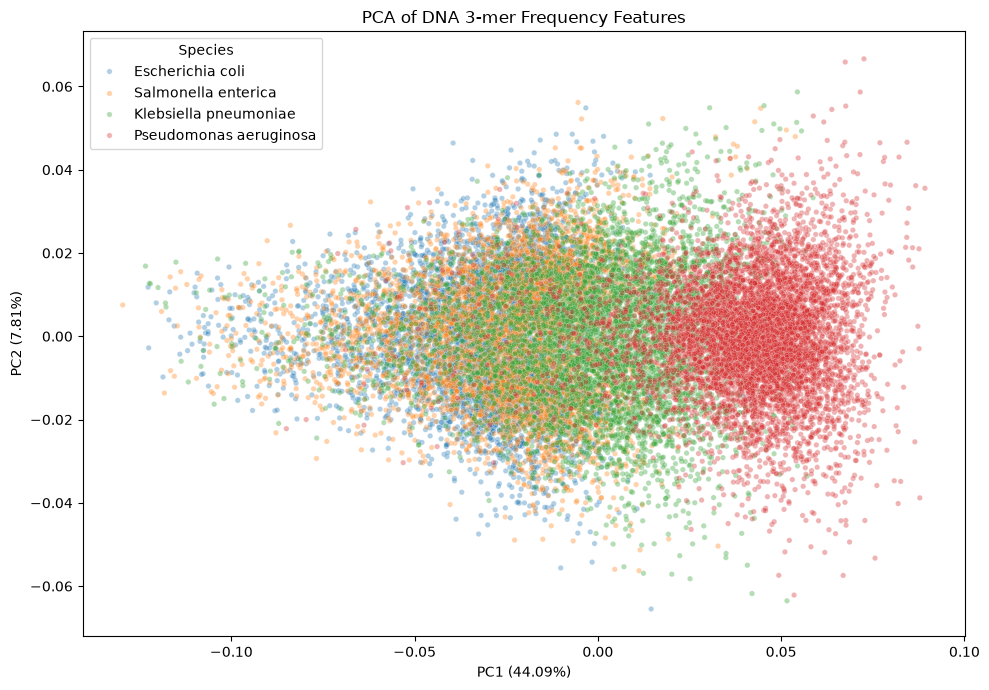

Total variance explained by PC1 and PC2: 51.9 %


In [184]:

from sklearn.decomposition import PCA

# Extract only the 64 k-mer features
X = features_df[kmer_columns].copy()

# Perform PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create visualization dataframe
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Species": features_df["Species"].values
})

# Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Species",
    alpha=0.35,
    s=15
)

plt.title("PCA of DNA 3-mer Frequency Features")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)
plt.tight_layout()
plt.show()

print(
    "Total variance explained by PC1 and PC2:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Top 15 most variable 3-mers:


,Between_Species_Variance
GCC,0.000103988078
GGC,0.000095692622
TTT,0.000081120534
AAA,0.000077768566
CGC,0.000068307303
GCG,0.000062777998
CCG,0.000055505715
CGG,0.000052844094
ATT,0.000041757382
TTA,0.000041024819


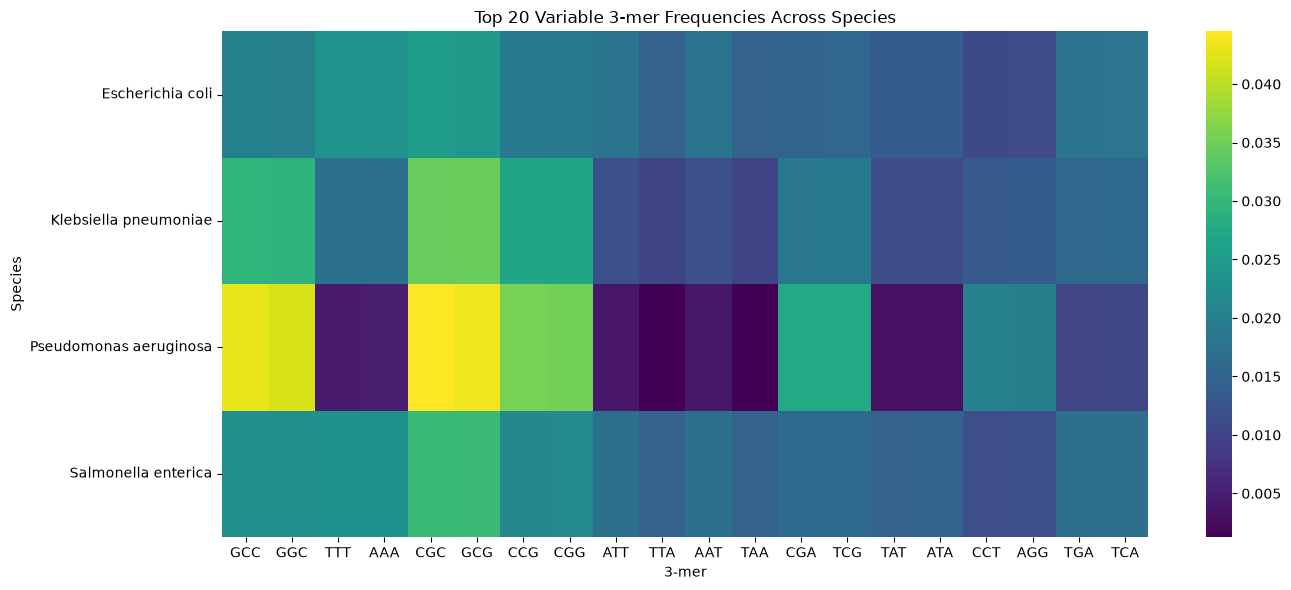

In [185]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate mean frequency of each 3-mer by species
species_kmer_means = features_df.groupby("Species")[kmer_columns].mean()

# Display the most variable 3-mers
kmer_variability = species_kmer_means.var(axis=0).sort_values(
    ascending=False
)

print("Top 15 most variable 3-mers:")
display(kmer_variability.head(15).to_frame("Between_Species_Variance"))

# Heatmap of the top 20 variable 3-mers
top_kmers = kmer_variability.head(20).index

plt.figure(figsize=(14, 6))

sns.heatmap(
    species_kmer_means[top_kmers],
    cmap="viridis",
    annot=False
)

plt.title("Top 20 Variable 3-mer Frequencies Across Species")
plt.xlabel("3-mer")
plt.ylabel("Species")
plt.tight_layout()
plt.show()


Correlation between GC and PCA components:


,GC_Content,PC1,PC2
GC_Content,1.0000,0.998,-0.0084
PC1,0.9980,1.000,0.0000
PC2,-0.0084,0.000,1.0000


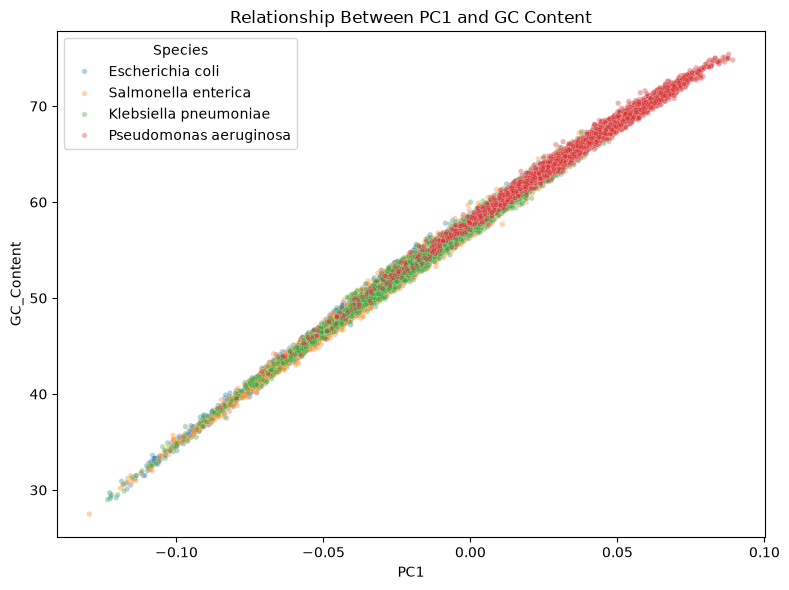

In [186]:

# Merge GC content with PCA coordinates
eda_df = pca_df.copy()
eda_df["GC_Content"] = fragments_df["GC_Content"].values

print("Correlation between GC and PCA components:")
display(
    eda_df[["GC_Content", "PC1", "PC2"]]
    .corr()
    .round(4)
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=eda_df,
    x="PC1",
    y="GC_Content",
    hue="Species",
    alpha=0.35,
    s=15
)

plt.title("Relationship Between PC1 and GC Content")
plt.tight_layout()
plt.show()


In [187]:
# Calculate mean 3-mer frequencies for each species
species_kmer_means = features_df.groupby("Species")[kmer_columns].mean()

# Calculate variance of each 3-mer across species
kmer_variability = (
    species_kmer_means
    .var(axis=0)
    .sort_values(ascending=False)
)

# Display the 15 most variable 3-mers
display(
    kmer_variability.head(15).to_frame(
        "Between_Species_Variance"
    )
)

,Between_Species_Variance
GCC,0.000103988078
GGC,0.000095692622
TTT,0.000081120534
AAA,0.000077768566
CGC,0.000068307303
GCG,0.000062777998
CCG,0.000055505715
CGG,0.000052844094
ATT,0.000041757382
TTA,0.000041024819


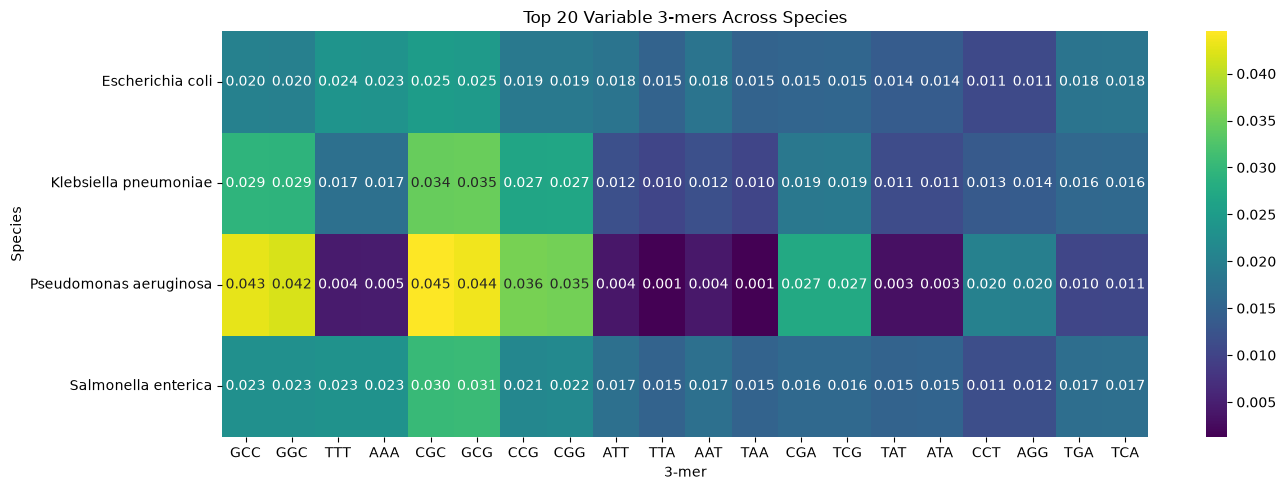

In [188]:
import matplotlib.pyplot as plt
import seaborn as sns

top_kmers = kmer_variability.head(20).index

plt.figure(figsize=(14, 5))

sns.heatmap(
    species_kmer_means[top_kmers],
    cmap="viridis",
    annot=True,
    fmt=".3f"
)

plt.title("Top 20 Variable 3-mers Across Species")
plt.xlabel("3-mer")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

In [189]:
kmer_gc_correlations = (
    features_df[kmer_columns]
    .corrwith(fragments_df["GC_Content"])
    .sort_values(key=abs, ascending=False)
)

display(
    kmer_gc_correlations.head(15).to_frame(
        "Correlation_with_GC"
    )
)

,Correlation_with_GC
TAA,-0.882452518653
TTA,-0.881873586009
AAT,-0.873639671919
ATT,-0.870269250221
GCC,0.869423304406
GGC,0.863627307523
CCG,0.841428795960
CGG,0.831145847206
CGC,0.829016617466
GCG,0.817782479230


In [190]:
top_kmers = kmer_variability.head(20).index

display(
    species_kmer_means[top_kmers].round(4)
)

,GCC,GGC,TTT,AAA,CGC,GCG,CCG,CGG,ATT,TTA,AAT,TAA,CGA,TCG,TAT,ATA,CCT,AGG,TGA,TCA
Species,,,,,,,,,,,,,,,,,,,,
Escherichia coli,0.0200,0.0199,0.0237,0.0235,0.0249,0.0247,0.0188,0.0187,0.0180,0.0148,0.0179,0.0148,0.0153,0.0155,0.0136,0.0137,0.0109,0.0109,0.0180,0.0181
Klebsiella pneumoniae,0.0293,0.0293,0.0170,0.0171,0.0345,0.0347,0.0267,0.0269,0.0118,0.0101,0.0119,0.0101,0.0186,0.0187,0.0111,0.0112,0.0133,0.0137,0.0157,0.0159
Pseudomonas aeruginosa,0.0429,0.0419,0.0044,0.0046,0.0445,0.0435,0.0356,0.0353,0.0039,0.0013,0.0040,0.0013,0.0274,0.0274,0.0030,0.0031,0.0202,0.0198,0.0103,0.0105
Salmonella enterica,0.0228,0.0228,0.0234,0.0232,0.0304,0.0305,0.0213,0.0216,0.0171,0.0149,0.0171,0.0148,0.0160,0.0160,0.0149,0.0150,0.0114,0.0116,0.0167,0.0169


In [191]:
# Calculate correlations within each species separately

within_species_correlations = {}

for species in features_df["Species"].unique():

    species_mask = features_df["Species"] == species

    species_data = features_df.loc[
        species_mask, kmer_columns
    ]

    species_gc = fragments_df.loc[
        species_mask, "GC_Content"
    ]

    correlations = species_data.corrwith(species_gc)

    within_species_correlations[species] = correlations

within_species_corr_df = pd.DataFrame(
    within_species_correlations
)

display(
    within_species_corr_df.loc[
        ["GCC", "GGC", "CGC", "TTT", "AAA", "TAA", "TTA"]
    ].round(3)
)

,Escherichia coli,Salmonella enterica,Klebsiella pneumoniae,Pseudomonas aeruginosa
GCC,0.649,0.690,0.763,0.738
GGC,0.648,0.678,0.756,0.732
CGC,0.757,0.788,0.793,0.765
TTT,-0.595,-0.611,-0.668,-0.688
AAA,-0.590,-0.630,-0.684,-0.645
TAA,-0.751,-0.759,-0.789,-0.690
TTA,-0.755,-0.754,-0.789,-0.702


In [192]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Safely combine GC values and k-mer features
analysis_df = features_df[
    ["Fragment_ID", "Species"] + kmer_columns
].merge(
    fragments_df[["Fragment_ID", "GC_Content"]],
    on="Fragment_ID",
    how="inner",
    validate="one_to_one"
)

# Remove the GC-associated component from each 3-mer
X_gc = analysis_df[["GC_Content"]].values

residual_features = pd.DataFrame(
    index=analysis_df.index
)

for kmer in kmer_columns:

    y = analysis_df[kmer].values

    model = LinearRegression()
    model.fit(X_gc, y)

    residual_features[kmer] = (
        y - model.predict(X_gc)
    )

# Compare residual 3-mer patterns between species
residual_features["Species"] = analysis_df["Species"].values

residual_species_means = (
    residual_features
    .groupby("Species")[kmer_columns]
    .mean()
)

display(residual_species_means.round(6))

,AAA,AAT,AAG,AAC,ATA,ATT,ATG,ATC,AGA,AGT,...,CTG,CTC,CGA,CGT,CGG,CGC,CCA,CCT,CCG,CCC
Species,,,,,,,,,,,,,,,,,,,,,
Escherichia coli,-0.000748,-0.000209,-0.000153,0.001334,-0.001585,-0.000139,-0.000061,-0.000098,-0.000176,0.000648,...,0.000752,-0.000665,-0.000382,0.000489,-0.000760,-0.000628,0.000806,-0.000760,-0.000556,-0.000629
Klebsiella pneumoniae,0.000891,-0.000215,-0.000338,-0.001381,0.000992,-0.000271,0.000164,0.001444,0.000544,-0.000657,...,0.001237,-0.000151,-0.001267,-0.000654,0.000544,0.000062,-0.000147,-0.001070,0.000352,0.000727
Pseudomonas aeruginosa,-0.000720,0.000081,0.000824,0.000050,-0.000245,0.000090,-0.000127,-0.001000,0.000002,0.000408,...,-0.001150,0.001347,0.001834,-0.001000,-0.000393,-0.001880,-0.000218,0.002067,-0.000286,0.000207
Salmonella enterica,0.000668,0.000331,-0.000547,0.000172,0.000746,0.000314,0.000042,-0.000197,-0.000431,-0.000427,...,-0.000590,-0.000937,-0.000613,0.001538,0.000638,0.002957,-0.000328,-0.000769,0.000515,-0.000462


In [193]:
residual_variance = (
    residual_species_means
    .var(axis=0)
    .sort_values(ascending=False)
)

display(
    residual_variance.head(20).to_frame(
        "GC_Adjusted_Between_Species_Variance"
    )
)

,GC_Adjusted_Between_Species_Variance
GCG,0.000005063914
CGC,0.000004204579
CCT,0.000002171767
AGC,0.000001904016
GCT,0.000001845891
CGA,0.000001814318
TCG,0.000001734184
AGG,0.000001598717
GCA,0.000001422572
ACG,0.000001414217


In [194]:
# Original between-species variance
original_variance = (
    species_kmer_means
    .var(axis=0)
)

# GC-adjusted between-species variance
adjusted_variance = (
    residual_species_means
    .var(axis=0)
)

# Combine both results
variance_comparison = pd.DataFrame({
    "Original_Variance": original_variance,
    "GC_Adjusted_Variance": adjusted_variance
})

# Calculate percentage reduction
variance_comparison["Reduction_Percent"] = (
    1 - (
        variance_comparison["GC_Adjusted_Variance"]
        / variance_comparison["Original_Variance"]
    )
) * 100

# Sort by original variance
variance_comparison = variance_comparison.sort_values(
    "Original_Variance",
    ascending=False
)

display(variance_comparison.head(20).round(4))

,Original_Variance,GC_Adjusted_Variance,Reduction_Percent
GCC,0.0001,0.0,99.6062
GGC,0.0001,0.0,99.6255
TTT,0.0001,0.0,98.9956
AAA,0.0001,0.0,99.0073
CGC,0.0001,0.0,93.8446
GCG,0.0001,0.0,91.9336
CCG,0.0001,0.0,99.5313
CGG,0.0001,0.0,99.0939
ATT,0.0000,0.0,99.8404
TTA,0.0000,0.0,98.9800


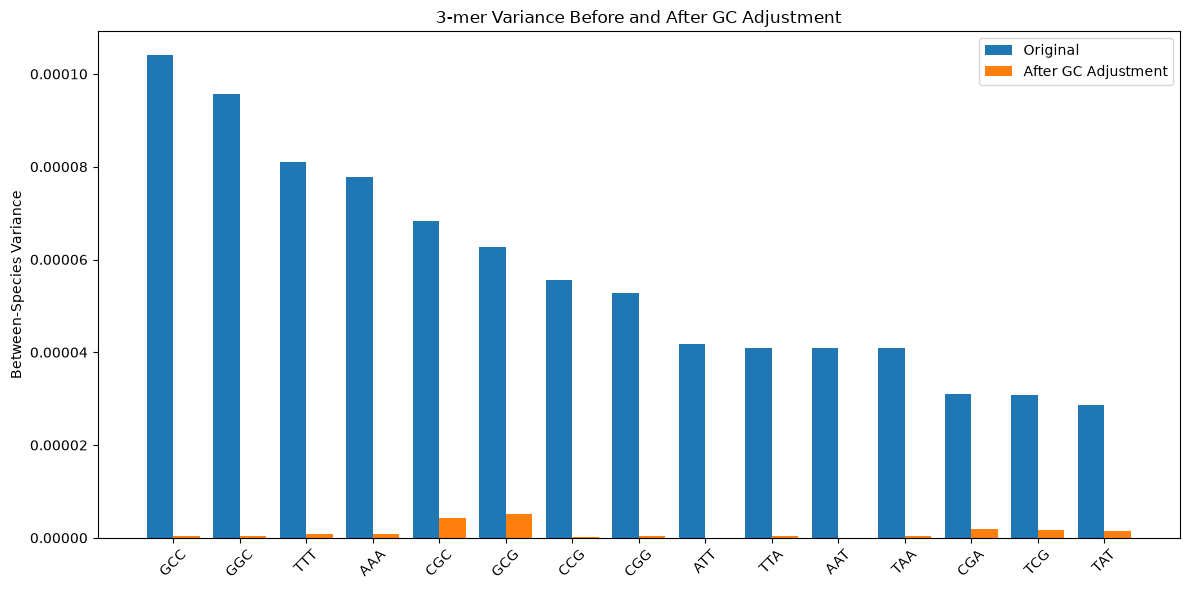

In [195]:
plt.figure(figsize=(12, 6))

top_features = variance_comparison.head(15)

x = range(len(top_features))

plt.bar(
    [i - 0.2 for i in x],
    top_features["Original_Variance"],
    width=0.4,
    label="Original"
)

plt.bar(
    [i + 0.2 for i in x],
    top_features["GC_Adjusted_Variance"],
    width=0.4,
    label="After GC Adjustment"
)

plt.xticks(
    list(x),
    top_features.index,
    rotation=45
)

plt.ylabel("Between-Species Variance")
plt.title("3-mer Variance Before and After GC Adjustment")
plt.legend()
plt.tight_layout()
plt.show()

In [196]:
# Full precision comparison for all 64 3-mers

variance_comparison_precise = pd.DataFrame({
    "Original_Variance": original_variance,
    "GC_Adjusted_Variance": adjusted_variance
})

variance_comparison_precise["Remaining_Percent"] = (
    variance_comparison_precise["GC_Adjusted_Variance"]
    / variance_comparison_precise["Original_Variance"]
) * 100

variance_comparison_precise["Reduction_Percent"] = (
    100 - variance_comparison_precise["Remaining_Percent"]
)

display(
    variance_comparison_precise
    .sort_values("Remaining_Percent", ascending=False)
    .round(8)
)

,Original_Variance,GC_Adjusted_Variance,Remaining_Percent,Reduction_Percent
ACG,0.00000097,0.00000141,145.93157296,-45.93157296
CGT,0.00000103,0.00000133,129.48789220,-29.48789220
GTG,0.00000088,0.00000105,118.82685786,-18.82685786
CAC,0.00000122,0.00000116,94.82351716,5.17648284
TGC,0.00000185,0.00000131,70.72348501,29.27651499
...,...,...,...,...
GGC,0.00009569,0.00000036,0.37448494,99.62551506
ATG,0.00000578,0.00000002,0.27881232,99.72118768
CAT,0.00000544,0.00000001,0.21033410,99.78966590
AAT,0.00004094,0.00000007,0.16792141,99.83207859


In [197]:
print("Median remaining variance (%):",
      variance_comparison_precise["Remaining_Percent"].median())

print("Mean remaining variance (%):",
      variance_comparison_precise["Remaining_Percent"].mean())

print("Features with >90% reduction:",
      (variance_comparison_precise["Reduction_Percent"] > 90).sum(),
      "out of", len(kmer_columns))

print("Features with >95% reduction:",
      (variance_comparison_precise["Reduction_Percent"] > 95).sum(),
      "out of", len(kmer_columns))

Median remaining variance (%): 9.062459045626042
Mean remaining variance (%): 19.399314934365893
Features with >90% reduction: 34 out of 64
Features with >95% reduction: 20 out of 64


In [198]:
# Rank features by remaining variance after GC adjustment

top_residual_features = (
    variance_comparison_precise
    .sort_values(
        "Remaining_Percent",
        ascending=False
    )
)

display(
    top_residual_features.head(15).round(6)
)

,Original_Variance,GC_Adjusted_Variance,Remaining_Percent,Reduction_Percent
ACG,0.000001,0.000001,145.931573,-45.931573
CGT,0.000001,0.000001,129.487892,-29.487892
GTG,0.000001,0.000001,118.826858,-18.826858
CAC,0.000001,0.000001,94.823517,5.176483
TGC,0.000002,0.000001,70.723485,29.276515
GCA,0.000002,0.000001,63.488302,36.511698
GAA,0.000002,0.000001,34.788085,65.211915
GCT,0.000006,0.000002,31.811587,68.188413
CTT,0.000001,0.000000,29.592476,70.407524
AGC,0.000007,0.000002,28.906362,71.093638


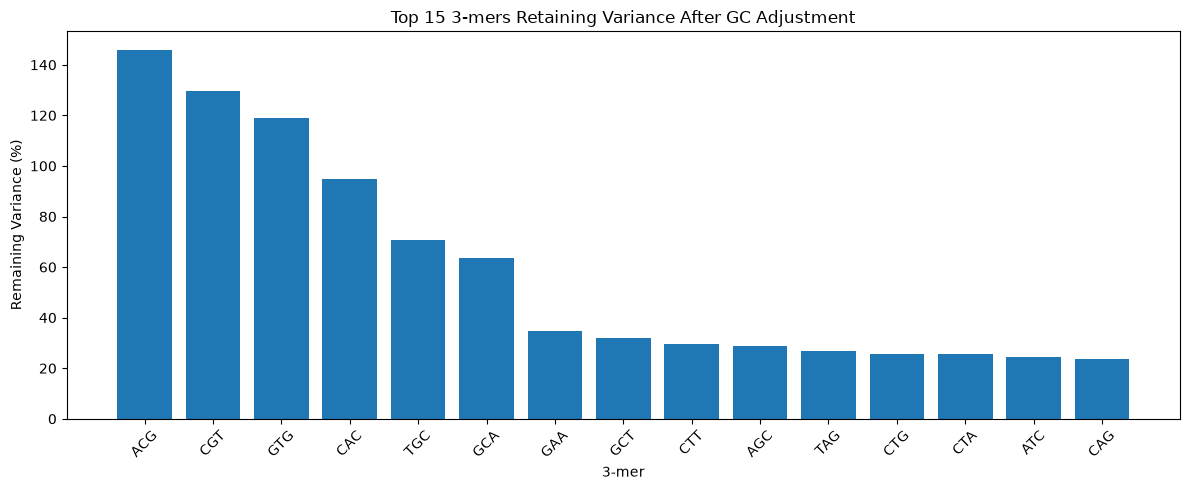

In [199]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

top15 = top_residual_features.head(15)

plt.bar(
    top15.index,
    top15["Remaining_Percent"]
)

plt.ylabel("Remaining Variance (%)")
plt.xlabel("3-mer")
plt.title("Top 15 3-mers Retaining Variance After GC Adjustment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [200]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\utils\_process_common.py:121: ResourceWarning: unclosed file <_io.BufferedWriter name=5>
  return out
c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\utils\_process_common.py:121: ResourceWarning: unclosed file <_io.BufferedReader name=7>
  return out
c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\utils\_process_common.py:121: ResourceWarning: unclosed file <_io.BufferedReader name=8>
  return out


In [201]:
import patsy
import statsmodels.formula.api as smf
import pandas as pd

candidate_kmers = [
    "ACG", "CGT", "GTG", "CAC",
    "TGC", "GCA", "GAA", "GCT", "AGC"
]

results = []

for kmer in candidate_kmers:

    model_gc = smf.ols(
        f'Q("{kmer}") ~ GC_Content',
        data=analysis_df
    ).fit()

    model_species = smf.ols(
        f'Q("{kmer}") ~ GC_Content + patsy.builtins.C(Species)',
        data=analysis_df,
        eval_env={"patsy": patsy}
    ).fit()

    results.append({
        "3-mer": kmer,
        "R2_GC_Only": model_gc.rsquared,
        "R2_GC_Species": model_species.rsquared,
        "Additional_R2": (
            model_species.rsquared - model_gc.rsquared
        ),
        "Species_P_Value": model_species.compare_f_test(
            model_gc
        )[1]
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Additional_R2",
        ascending=False
    ).round(6)
)

,3-mer,R2_GC_Only,R2_GC_Species,Additional_R2,Species_P_Value
1,CGT,0.001722,0.094812,0.093090,0.0
0,ACG,0.005211,0.086051,0.080840,0.0
5,GCA,0.110636,0.154512,0.043876,0.0
4,TGC,0.086841,0.127918,0.041077,0.0
8,AGC,0.184942,0.225090,0.040148,0.0
7,GCT,0.160419,0.199993,0.039573,0.0
2,GTG,0.006673,0.045361,0.038689,0.0
3,CAC,0.027298,0.062750,0.035452,0.0
6,GAA,0.103233,0.129794,0.026560,0.0


In [202]:
pd.set_option("display.precision", 12)

display(
    results_df[
        ["3-mer", "Additional_R2", "Species_P_Value"]
    ].sort_values(
        "Additional_R2",
        ascending=False
    )
)

,3-mer,Additional_R2,Species_P_Value
1,CGT,0.093089844188,0.000000000000e+00
0,ACG,0.080839969719,0.000000000000e+00
5,GCA,0.043875912865,8.190664851505e-231
4,TGC,0.041076991623,6.105922105034e-210
8,AGC,0.040147571714,1.914812816773e-230
7,GCT,0.039573472458,2.994990197993e-220
2,GTG,0.038688626516,3.786769780525e-181
3,CAC,0.035451798593,2.883715684672e-169
6,GAA,0.026560219130,5.370384791001e-137


In [203]:
import statsmodels.formula.api as smf
import pandas as pd

results_all = []

for kmer in kmer_columns:

    # Model 1: GC only
    model_gc = smf.ols(
        f'Q("{kmer}") ~ GC_Content',
        data=analysis_df
    ).fit()

    # Model 2: Species only
    model_species = smf.ols(
        f'Q("{kmer}") ~ patsy.builtins.C(Species)',
        data=analysis_df,
        eval_env=1
    ).fit()

    # Model 3: GC + Species
    model_combined = smf.ols(
        f'Q("{kmer}") ~ GC_Content + patsy.builtins.C(Species)',
        data=analysis_df,
        eval_env=1
    ).fit()

    results_all.append({
        "3-mer": kmer,
        "R2_GC_Only": model_gc.rsquared,
        "R2_Species_Only": model_species.rsquared,
        "R2_Combined": model_combined.rsquared,
        "Additional_R2_from_Species":
            model_combined.rsquared - model_gc.rsquared,
        "Additional_R2_from_GC":
            model_combined.rsquared - model_species.rsquared
    })

all_results_df = pd.DataFrame(results_all)

display(
    all_results_df.sort_values(
        "Additional_R2_from_Species",
        ascending=False
    ).round(6)
)

,3-mer,R2_GC_Only,R2_Species_Only,R2_Combined,Additional_R2_from_Species,Additional_R2_from_GC
61,CCT,0.263277,0.361080,0.365935,0.102658,0.004855
57,CGT,0.001722,0.032811,0.094812,0.093090,0.062001
55,CTC,0.175866,0.261656,0.262207,0.086341,0.000551
10,AGG,0.255272,0.330676,0.337969,0.082698,0.007293
14,ACG,0.005211,0.028592,0.086051,0.080840,0.057459
...,...,...,...,...,...,...
62,CCG,0.708002,0.435966,0.709972,0.001970,0.274006
49,CAT,0.237583,0.162053,0.238347,0.000764,0.076295
1,AAT,0.763246,0.478423,0.763966,0.000720,0.285543
5,ATT,0.757369,0.476281,0.758058,0.000689,0.281777


In [204]:
top_kmers = (
    all_results_df
    .sort_values(
        "Additional_R2_from_Species",
        ascending=False
    )
    .head(10)["3-mer"]
    .tolist()
)

species_means = (
    analysis_df
    .groupby("Species")[top_kmers]
    .mean()
    .T
)

display(species_means.round(6))

Species,Escherichia coli,Klebsiella pneumoniae,Pseudomonas aeruginosa,Salmonella enterica
CCT,0.010870,0.013310,0.020179,0.011449
CGT,0.015768,0.014791,0.014673,0.016853
CTC,0.009211,0.011497,0.015402,0.009318
AGG,0.010915,0.013652,0.019765,0.011604
ACG,0.015790,0.014667,0.015235,0.016973
GAG,0.009156,0.011597,0.014524,0.009317
CGA,0.015289,0.018588,0.027368,0.015953
TCG,0.015461,0.018674,0.027418,0.015962
GCA,0.020695,0.020199,0.022006,0.018390
GCG,0.024705,0.034688,0.043544,0.030540


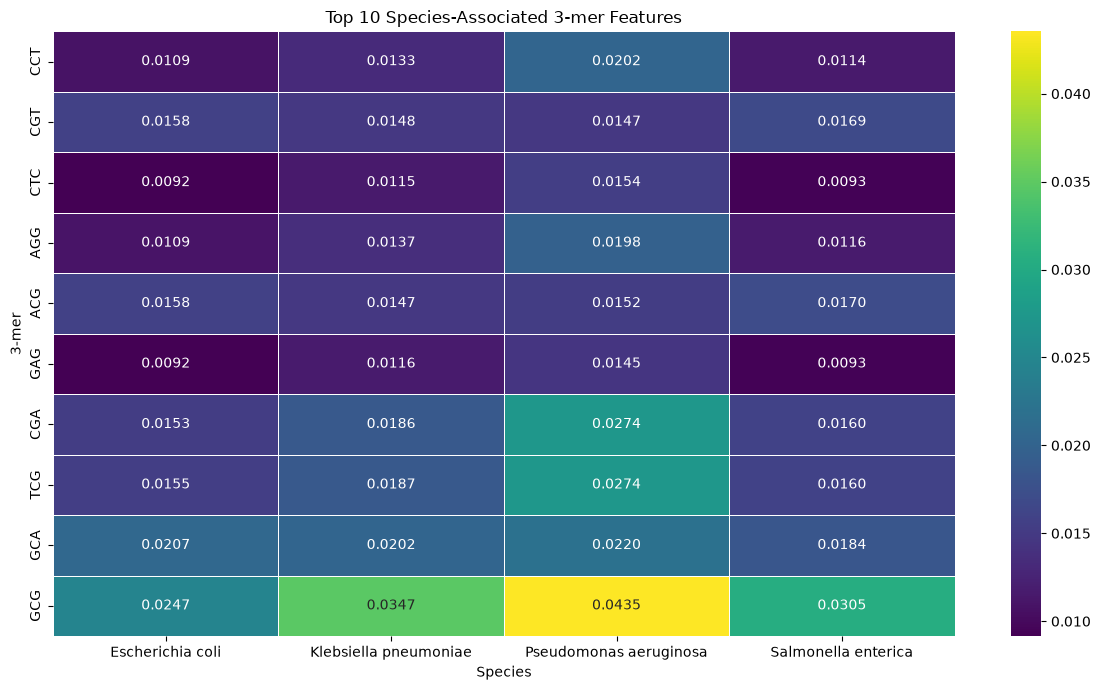

In [205]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.heatmap(
    species_means,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    linewidths=0.5
)

plt.title(
    "Top 10 Species-Associated 3-mer Features"
)

plt.xlabel("Species")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

In [206]:
import statsmodels.formula.api as smf
import pandas as pd

# Create a copy of the analysis data
residuals_df = analysis_df[["Fragment_ID", "Species"]].copy()

# Calculate residuals for all 64 3-mer features
for kmer in kmer_columns:

    model = smf.ols(
        f'Q("{kmer}") ~ GC_Content',
        data=analysis_df
    ).fit()

    residuals_df[kmer] = model.resid

print("Residuals DataFrame created successfully!")
print("Shape:", residuals_df.shape)

display(residuals_df.head())

Residuals DataFrame created successfully!
Shape: (21077, 66)


,Fragment_ID,Species,AAA,AAT,AAG,AAC,ATA,ATT,ATG,ATC,...,CTG,CTC,CGA,CGT,CGG,CGC,CCA,CCT,CCG,CCC
0,NC_000913.3_fragment_1,Escherichia coli,0.015745758071,-0.002142454645,-0.005818037275,0.005550578224,-0.003355356869,0.005857343226,-0.001495569937,-0.006732722740,...,0.007660334432,-0.003839444706,0.002421760843,-0.003252737877,-0.001350590617,-0.004402219556,0.005240555171,-0.004578289752,0.004830814136,-0.000874498323
1,NC_000913.3_fragment_2,Escherichia coli,-0.005307926058,0.004112064215,0.006815609250,-0.002595803292,-0.003466234366,-0.000896701725,0.002336544828,0.001803133657,...,0.008769372472,0.002511874344,0.000857720895,0.002696957900,-0.003916285467,-0.006702223366,-0.002470238671,-0.002600164834,-0.005815651085,0.001149965075
2,NC_000913.3_fragment_3,Escherichia coli,0.001151011733,-0.002066137296,0.001488598027,-0.001045055645,-0.004450662236,-0.002073977108,0.013931019499,-0.005481203052,...,0.001218724795,0.004860491043,0.000669017660,0.002729368601,0.003429899903,-0.004985179301,-0.007117940503,-0.002065663539,0.001564198205,-0.004351653688
3,NC_000913.3_fragment_4,Escherichia coli,0.004177615983,0.000705983447,0.005518735411,-0.002586688015,-0.008284231020,0.000727523968,0.002292820000,0.000402121868,...,0.005727199285,0.000741127890,-0.001958569454,-0.002385362935,0.005131556604,-0.008528544418,-0.007286503015,-0.001788505860,0.000151082525,-0.003996647364
4,NC_000913.3_fragment_5,Escherichia coli,0.005714118030,-0.003903967849,0.004811601234,0.005420228772,-0.006472246390,-0.000896701725,-0.001671471204,-0.004208890391,...,0.009771376481,-0.000494137680,0.004865736927,0.003698961908,0.002095738581,-0.007704227374,-0.001468234663,-0.006608180866,-0.002809639061,-0.007868070997


Species,Escherichia coli,Klebsiella pneumoniae,Pseudomonas aeruginosa,Salmonella enterica
ACG,0.00047354,-0.00094666,-0.00078283,0.00159306
CGT,0.00048874,-0.00065440,-0.00099955,0.00153821
GTG,0.00147448,0.00003133,-0.00042128,-0.00089987
CAC,0.00156959,-0.00032041,-0.00016317,-0.00093873
TGC,0.00170073,-0.00006754,-0.00052087,-0.00087943
GCA,0.00181450,-0.00022603,-0.00051623,-0.00082069
GAA,0.00038247,-0.00109822,0.00096731,-0.00041120
GCT,-0.00040645,0.00199142,-0.00114566,-0.00031328
AGC,-0.00042323,0.00200034,-0.00122208,-0.00020847


c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


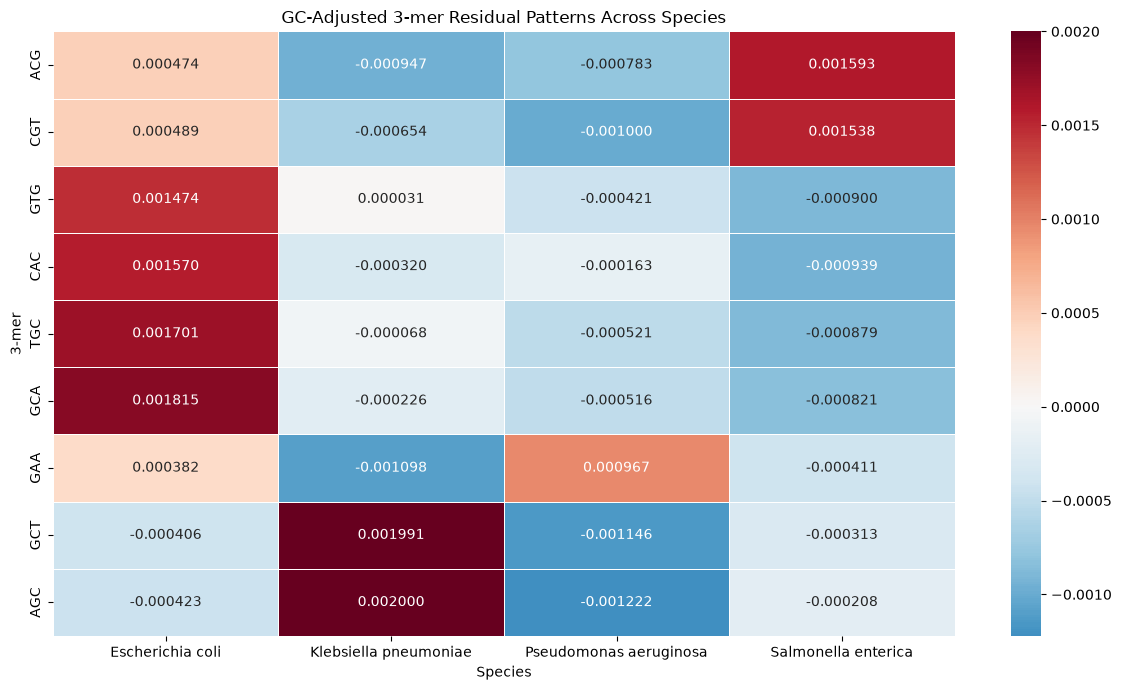

In [207]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate mean residuals for each species
residual_means = (
    residuals_df
    .groupby("Species")[candidate_kmers]
    .mean()
    .T
)

display(residual_means.round(8))

# Plot residual heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    residual_means,
    annot=True,
    fmt=".6f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title(
    "GC-Adjusted 3-mer Residual Patterns Across Species"
)

plt.xlabel("Species")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

In [208]:
residual_means = (
    residuals_df
    .groupby("Species")[top_kmers]
    .mean()
    .T
)

display(residual_means.round(8))

Species,Escherichia coli,Klebsiella pneumoniae,Pseudomonas aeruginosa,Salmonella enterica
CCT,-0.00075990,-0.00106986,0.00206703,-0.00076897
CGT,0.00048874,-0.00065440,-0.00099955,0.00153821
CTC,-0.00066497,-0.00015110,0.00134719,-0.00093670
AGG,-0.00081990,-0.00073701,0.00177482,-0.00069901
ACG,0.00047354,-0.00094666,-0.00078283,0.00159306
GAG,-0.00073195,0.00019602,0.00106986,-0.00089488
CGA,-0.00038231,-0.00126679,0.00183357,-0.00061318
TCG,-0.00026391,-0.00125722,0.00177614,-0.00066272
GCA,0.00181450,-0.00022603,-0.00051623,-0.00082069
GCG,-0.00093766,0.00053926,-0.00214929,0.00307775


c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


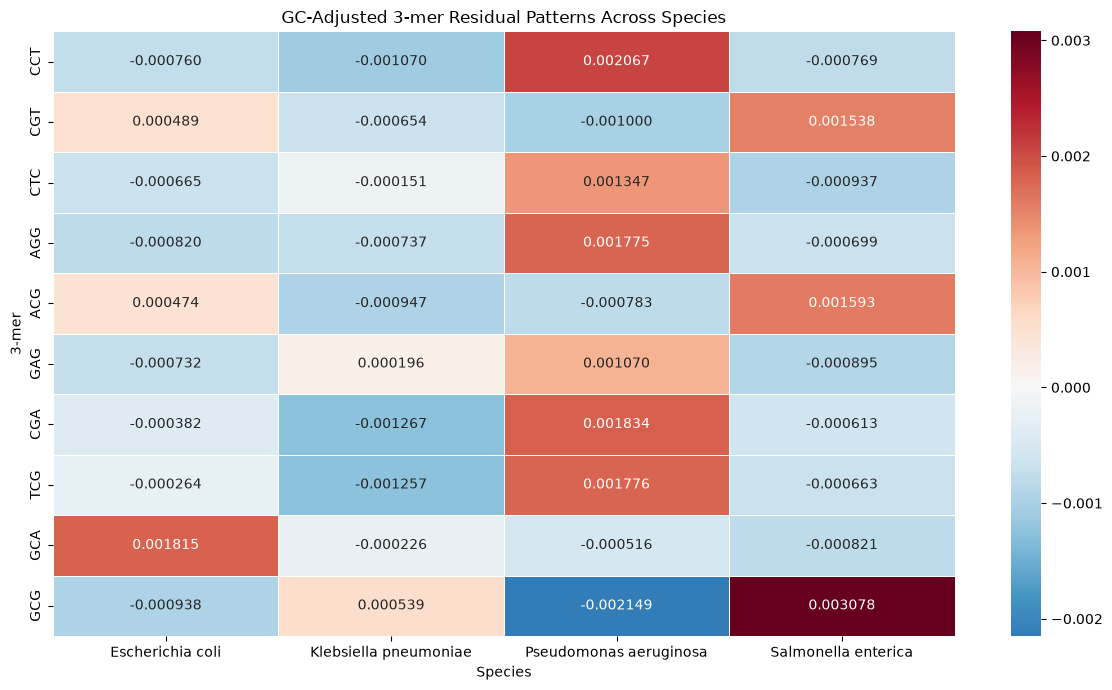

In [209]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.heatmap(
    residual_means,
    annot=True,
    fmt=".6f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title(
    "GC-Adjusted 3-mer Residual Patterns Across Species"
)

plt.xlabel("Species")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

In [210]:
# Calculate residual range across the four species
residual_summary = pd.DataFrame({
    "Mean_Residual": residual_means.mean(axis=1),
    "Min_Residual": residual_means.min(axis=1),
    "Max_Residual": residual_means.max(axis=1),
    "Residual_Range": (
        residual_means.max(axis=1) -
        residual_means.min(axis=1)
    )
})

residual_summary.index.name = "3-mer"

residual_summary = residual_summary.sort_values(
    "Residual_Range",
    ascending=False
)

display(residual_summary.head(20).round(8))

,Mean_Residual,Min_Residual,Max_Residual,Residual_Range
3-mer,,,,
GCG,0.00013252,-0.00214929,0.00307775,0.00522704
CCT,-0.00013292,-0.00106986,0.00206703,0.00313689
CGA,-0.00010718,-0.00126679,0.00183357,0.00310036
TCG,-0.00010193,-0.00125722,0.00177614,0.00303336
GCA,0.00006289,-0.00082069,0.00181450,0.00263519
AGG,-0.00012028,-0.00081990,0.00177482,0.00259472
ACG,0.00008428,-0.00094666,0.00159306,0.00253972
CGT,0.00009325,-0.00099955,0.00153821,0.00253776
CTC,-0.00010140,-0.00093670,0.00134719,0.00228388


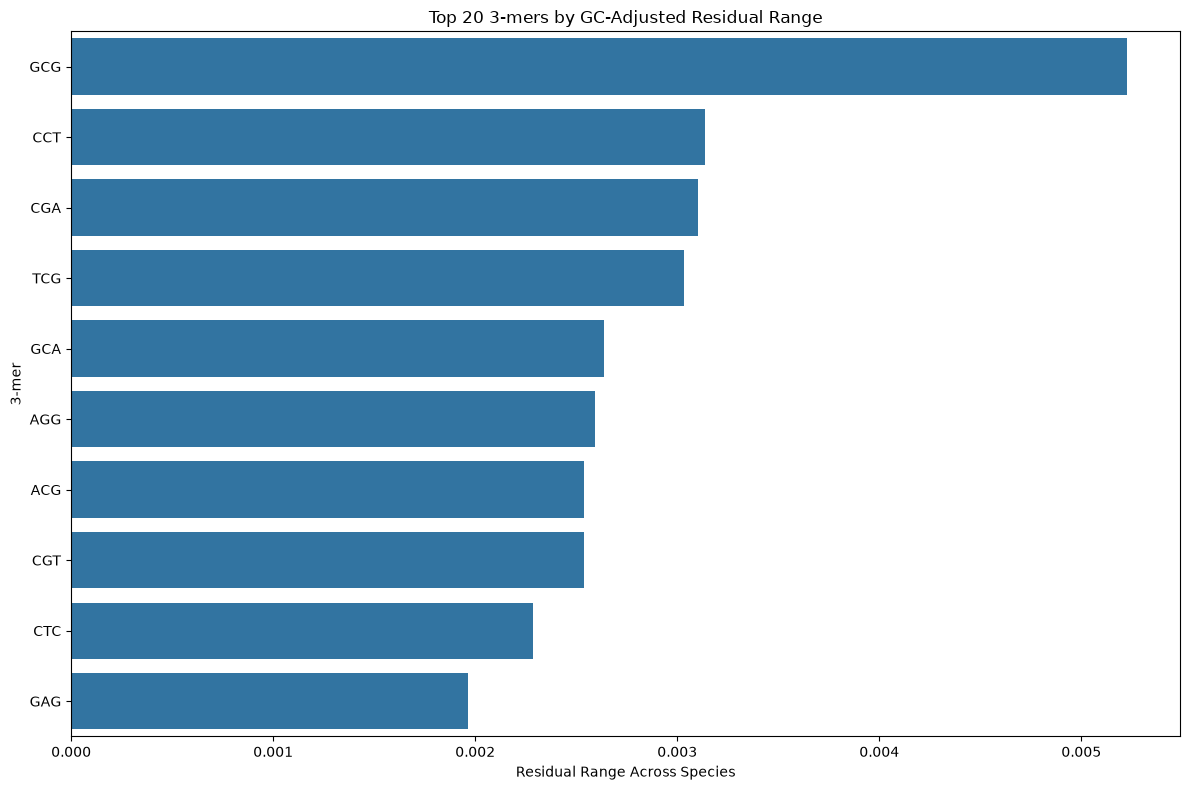

In [211]:
import matplotlib.pyplot as plt
import seaborn as sns

top20_residual = residual_summary.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    x="Residual_Range",
    y=top20_residual.index,
    data=top20_residual.reset_index()
)

plt.title("Top 20 3-mers by GC-Adjusted Residual Range")
plt.xlabel("Residual Range Across Species")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

c:\Users\omer\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


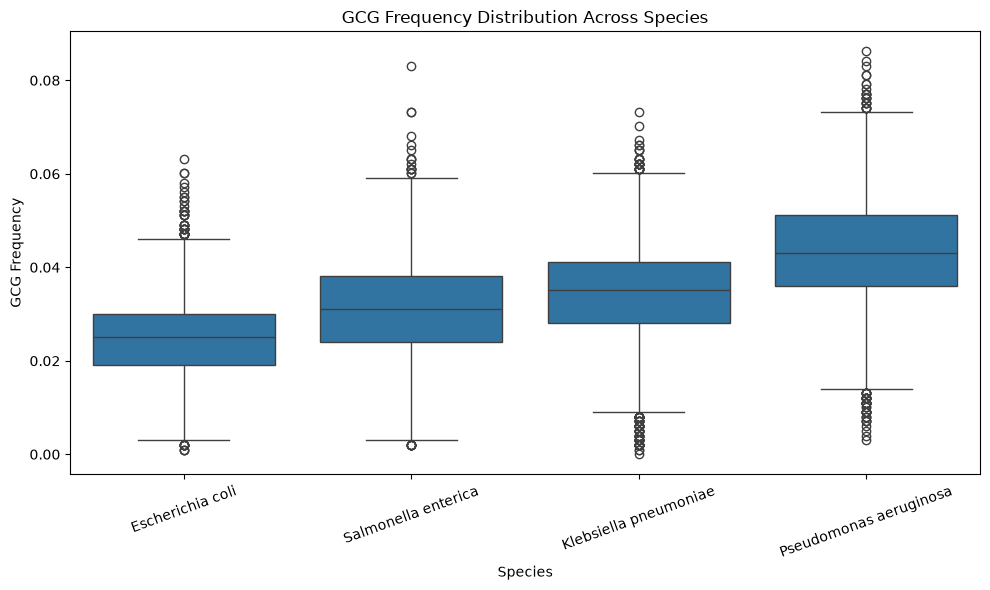

In [212]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x="Species",
    y="GCG"
)

plt.title("GCG Frequency Distribution Across Species")
plt.xlabel("Species")
plt.ylabel("GCG Frequency")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

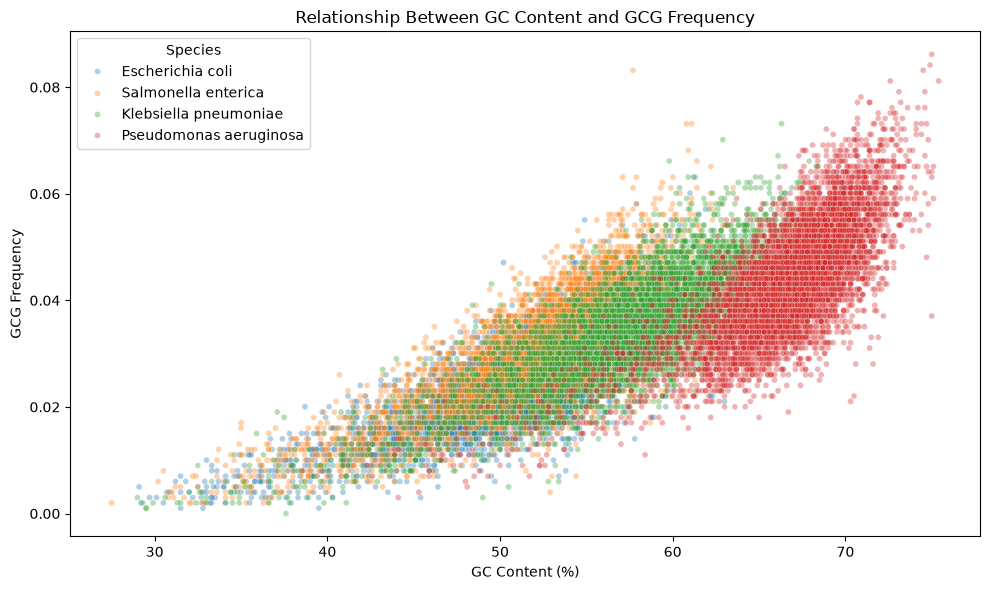

In [213]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x="GC_Content",
    y="GCG",
    hue="Species",
    alpha=0.35,
    s=18
)

plt.title("Relationship Between GC Content and GCG Frequency")
plt.xlabel("GC Content (%)")
plt.ylabel("GCG Frequency")

plt.tight_layout()
plt.show()

In [214]:
gcg_summary = (
    analysis_df
    .groupby("Species")["GCG"]
    .agg(
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

display(gcg_summary.round(6))

,Mean,Median,Std,Min,Max
Species,,,,,
Escherichia coli,0.024705,0.025050,0.008574,0.001002,0.063126
Klebsiella pneumoniae,0.034688,0.035070,0.010515,0.000000,0.073146
Pseudomonas aeruginosa,0.043544,0.043086,0.011199,0.003006,0.086172
Salmonella enterica,0.030540,0.031062,0.010614,0.002004,0.083166


In [215]:
species_ranges = (
    analysis_df
    .groupby("Species")["GCG"]
    .agg(["min", "max"])
)

species_names = species_ranges.index.tolist()

overlap_results = []

for i in range(len(species_names)):
    for j in range(i + 1, len(species_names)):

        s1 = species_names[i]
        s2 = species_names[j]

        lower = max(
            species_ranges.loc[s1, "min"],
            species_ranges.loc[s2, "min"]
        )

        upper = min(
            species_ranges.loc[s1, "max"],
            species_ranges.loc[s2, "max"]
        )

        overlap = max(0, upper - lower)

        overlap_results.append({
            "Species_1": s1,
            "Species_2": s2,
            "Overlap_Range": overlap,
            "Ranges_Overlap": overlap > 0
        })

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df)

,Species_1,Species_2,Overlap_Range,Ranges_Overlap
0,Escherichia coli,Klebsiella pneumoniae,0.062124248497,True
1,Escherichia coli,Pseudomonas aeruginosa,0.060120240481,True
2,Escherichia coli,Salmonella enterica,0.061122244489,True
3,Klebsiella pneumoniae,Pseudomonas aeruginosa,0.070140280561,True
4,Klebsiella pneumoniae,Salmonella enterica,0.071142284569,True
5,Pseudomonas aeruginosa,Salmonella enterica,0.080160320641,True


In [216]:
gcg_gc_correlation = (
    analysis_df
    .groupby("Species")
    .apply(
        lambda x: x["GC_Content"].corr(x["GCG"]),
        include_groups=False
    )
)

display(gcg_gc_correlation.rename("GC_GCG_Correlation"))

Species
Escherichia coli          0.757249386730
Klebsiella pneumoniae     0.801435779274
Pseudomonas aeruginosa    0.747819835219
Salmonella enterica       0.780177266809
Name: GC_GCG_Correlation, dtype: float64

In [217]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

gcg_nonlinear_results = []

for species, group in analysis_df.groupby("Species"):

    # Linear model
    linear_model = smf.ols(
        "GCG ~ GC_Content",
        data=group
    ).fit()

    # Quadratic model
    quadratic_model = smf.ols(
        "GCG ~ GC_Content + I(GC_Content**2)",
        data=group
    ).fit()

    gcg_nonlinear_results.append({
        "Species": species,
        "Linear_R2": linear_model.rsquared,
        "Quadratic_R2": quadratic_model.rsquared,
        "R2_Improvement": (
            quadratic_model.rsquared -
            linear_model.rsquared
        ),
        "Quadratic_Term_P": quadratic_model.pvalues[
            "I(GC_Content ** 2)"
        ]
    })

gcg_nonlinear_df = pd.DataFrame(gcg_nonlinear_results)

display(gcg_nonlinear_df.round(6))

,Species,Linear_R2,Quadratic_R2,R2_Improvement,Quadratic_Term_P
0,Escherichia coli,0.573427,0.581072,0.007646,0.0
1,Klebsiella pneumoniae,0.642299,0.645531,0.003232,0.0
2,Pseudomonas aeruginosa,0.559235,0.583056,0.023822,0.0
3,Salmonella enterica,0.608677,0.611156,0.002479,0.0


In [218]:
import statsmodels.formula.api as smf
import pandas as pd

model_comparison = []

for species, group in analysis_df.groupby("Species"):

    linear_model = smf.ols(
        "GCG ~ GC_Content",
        data=group
    ).fit()

    quadratic_model = smf.ols(
        "GCG ~ GC_Content + I(GC_Content**2)",
        data=group
    ).fit()

    model_comparison.append({
        "Species": species,

        "Linear_R2": linear_model.rsquared,
        "Quadratic_R2": quadratic_model.rsquared,

        "Linear_Adjusted_R2": linear_model.rsquared_adj,
        "Quadratic_Adjusted_R2": quadratic_model.rsquared_adj,

        "Linear_AIC": linear_model.aic,
        "Quadratic_AIC": quadratic_model.aic,

        "Linear_BIC": linear_model.bic,
        "Quadratic_BIC": quadratic_model.bic,

        "AIC_Improvement": (
            linear_model.aic - quadratic_model.aic
        ),

        "BIC_Improvement": (
            linear_model.bic - quadratic_model.bic
        )
    })

comparison_df = pd.DataFrame(model_comparison)

display(comparison_df.round(4))

,Species,Linear_R2,Quadratic_R2,Linear_Adjusted_R2,Quadratic_Adjusted_R2,Linear_AIC,Quadratic_AIC,Linear_BIC,Quadratic_BIC,AIC_Improvement,BIC_Improvement
0,Escherichia coli,0.5734,0.5811,0.5733,0.5809,-34953.911000000000,-35035.847399999999,-34941.025600000001,-35016.519399999997,81.9365,75.4938
1,Klebsiella pneumoniae,0.6423,0.6455,0.6422,0.6454,-38797.447000000000,-38843.686199999996,-38784.290399999998,-38823.951399999998,46.2393,39.6610
2,Pseudomonas aeruginosa,0.5592,0.5831,0.5592,0.5829,-43627.447099999998,-43973.488200000000,-43613.962000000000,-43953.260499999997,346.0410,339.2985
3,Salmonella enterica,0.6087,0.6112,0.6086,0.6110,-34926.505400000002,-34955.376700000001,-34913.529100000000,-34935.912100000001,28.8712,22.3831


In [219]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Features and target
X_gc = analysis_df[["GC_Content"]]

X_kmer = analysis_df[kmer_columns]

X_combined = analysis_df[
    ["GC_Content"] + kmer_columns
]

y = analysis_df["Species"]

print("GC features:", X_gc.shape)
print("3-mer features:", X_kmer.shape)
print("Combined features:", X_combined.shape)
print("\nSpecies distribution:")
display(y.value_counts())

GC features: (21077, 1)
3-mer features: (21077, 64)
Combined features: (21077, 65)

Species distribution:


Species
Pseudomonas aeruginosa    6264
Klebsiella pneumoniae     5315
Salmonella enterica       4857
Escherichia coli          4641
Name: count, dtype: int64

In [220]:
print("analysis_df columns:")
print(analysis_df.columns.tolist())

print("\nfeatures_df columns:")
print(features_df.columns.tolist())

analysis_df columns:
['Fragment_ID', 'Species', 'AAA', 'AAT', 'AAG', 'AAC', 'ATA', 'ATT', 'ATG', 'ATC', 'AGA', 'AGT', 'AGG', 'AGC', 'ACA', 'ACT', 'ACG', 'ACC', 'TAA', 'TAT', 'TAG', 'TAC', 'TTA', 'TTT', 'TTG', 'TTC', 'TGA', 'TGT', 'TGG', 'TGC', 'TCA', 'TCT', 'TCG', 'TCC', 'GAA', 'GAT', 'GAG', 'GAC', 'GTA', 'GTT', 'GTG', 'GTC', 'GGA', 'GGT', 'GGG', 'GGC', 'GCA', 'GCT', 'GCG', 'GCC', 'CAA', 'CAT', 'CAG', 'CAC', 'CTA', 'CTT', 'CTG', 'CTC', 'CGA', 'CGT', 'CGG', 'CGC', 'CCA', 'CCT', 'CCG', 'CCC', 'GC_Content']

features_df columns:
['Fragment_ID', 'Genome_ID', 'Species', 'Strain', 'Assembly_Accession', 'Start_Position', 'End_Position', 'Length', 'AAA', 'AAT', 'AAG', 'AAC', 'ATA', 'ATT', 'ATG', 'ATC', 'AGA', 'AGT', 'AGG', 'AGC', 'ACA', 'ACT', 'ACG', 'ACC', 'TAA', 'TAT', 'TAG', 'TAC', 'TTA', 'TTT', 'TTG', 'TTC', 'TGA', 'TGT', 'TGG', 'TGC', 'TCA', 'TCT', 'TCG', 'TCC', 'GAA', 'GAT', 'GAG', 'GAC', 'GTA', 'GTT', 'GTG', 'GTC', 'GGA', 'GGT', 'GGG', 'GGC', 'GCA', 'GCT', 'GCG', 'GCC', 'CAA', 'CAT', 'C

In [221]:
analysis_df = analysis_df.merge(
    features_df[["Fragment_ID", "Genome_ID"]],
    on="Fragment_ID",
    how="left",
    validate="one_to_one"
)

print("Missing Genome_ID:", analysis_df["Genome_ID"].isna().sum())
print("Unique genomes:", analysis_df["Genome_ID"].nunique())

Missing Genome_ID: 0
Unique genomes: 4


In [222]:
genome_summary = (
    analysis_df
    .groupby(["Species", "Genome_ID"])
    .size()
    .reset_index(name="Fragment_Count")
)

display(genome_summary)

print("Total independent genomes:", analysis_df["Genome_ID"].nunique())
print("\nGenomes per species:")
print(analysis_df.groupby("Species")["Genome_ID"].nunique())

,Species,Genome_ID,Fragment_Count
0,Escherichia coli,NC_000913.3,4641
1,Klebsiella pneumoniae,NC_009648.1,5315
2,Pseudomonas aeruginosa,NC_002516.2,6264
3,Salmonella enterica,NC_003197.2,4857


Total independent genomes: 4

Genomes per species:
Species
Escherichia coli          1
Klebsiella pneumoniae     1
Pseudomonas aeruginosa    1
Salmonella enterica       1
Name: Genome_ID, dtype: int64


In [223]:
# Define feature groups

metadata_columns = [
    "Fragment_ID",
    "Genome_ID",
    "Species"
]

kmer_columns = [
    col for col in analysis_df.columns
    if len(col) == 3 and set(col).issubset({"A", "T", "G", "C"})
]

# GC-only features
X_gc = analysis_df[["GC_Content"]].copy()

# 3-mer-only features
X_kmer = analysis_df[kmer_columns].copy()

# Combined features
X_combined = analysis_df[["GC_Content"] + kmer_columns].copy()

# Target labels
y = analysis_df["Species"].copy()

# Verify datasets
print("GC-only shape:", X_gc.shape)
print("3-mer-only shape:", X_kmer.shape)
print("Combined shape:", X_combined.shape)
print("Target shape:", y.shape)

print("\nNumber of 3-mer features:", len(kmer_columns))
print("\nSpecies distribution:")
print(y.value_counts())

GC-only shape: (21077, 1)
3-mer-only shape: (21077, 64)
Combined shape: (21077, 65)
Target shape: (21077,)

Number of 3-mer features: 64

Species distribution:
Species
Pseudomonas aeruginosa    6264
Klebsiella pneumoniae     5315
Salmonella enterica       4857
Escherichia coli          4641
Name: count, dtype: int64


In [224]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Create sample indices
indices = np.arange(len(y))

# Stratified 80/20 split
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 16861
Testing samples: 4216

Training distribution:
Species
Pseudomonas aeruginosa    5011
Klebsiella pneumoniae     4252
Salmonella enterica       3885
Escherichia coli          3713
Name: count, dtype: int64

Testing distribution:
Species
Pseudomonas aeruginosa    1253
Klebsiella pneumoniae     1063
Salmonella enterica        972
Escherichia coli           928
Name: count, dtype: int64


In [225]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

feature_sets = {
    "GC-only": X_gc,
    "3-mer-only": X_kmer,
    "Combined": X_combined
}

results = []

trained_models = {}

for name, X in feature_sets.items():

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")

    results.append({
        "Feature_Set": name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Macro_F1",
        ascending=False
    )
)

,Feature_Set,Accuracy,Macro_F1
1,3-mer-only,0.821869070209,0.809805381159
2,Combined,0.821631878558,0.809547448843
0,GC-only,0.573766603416,0.542998871778


Classification Report - 3-mer-only
                        precision    recall  f1-score   support

      Escherichia coli     0.7361    0.7543    0.7451       928
 Klebsiella pneumoniae     0.8080    0.7996    0.8038      1063
Pseudomonas aeruginosa     0.9856    0.9832    0.9844      1253
   Salmonella enterica     0.7092    0.7027    0.7059       972

              accuracy                         0.8219      4216
             macro avg     0.8097    0.8100    0.8098      4216
          weighted avg     0.8222    0.8219    0.8220      4216



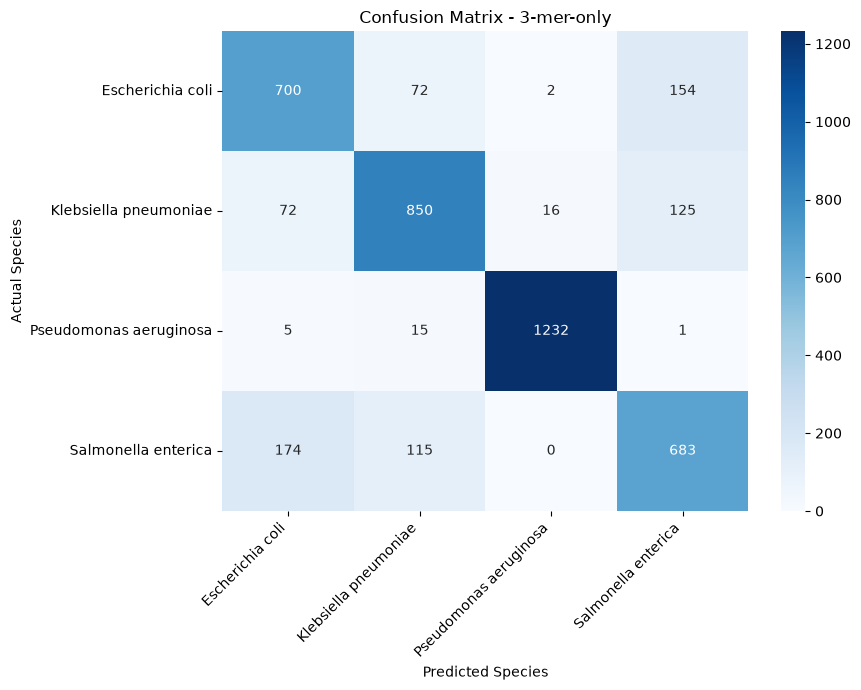

In [226]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Analyze the best-performing feature set
best_model = trained_models["3-mer-only"]

X_test_best = X_kmer.iloc[test_idx]
y_pred_best = best_model.predict(X_test_best)

# Classification report
print("Classification Report - 3-mer-only")
print(
    classification_report(
        y_test,
        y_pred_best,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=best_model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Confusion Matrix - 3-mer-only")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [227]:
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=best_model.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=best_model.classes_,
    columns=best_model.classes_
)

print(cm_df.to_string())

                        Escherichia coli  Klebsiella pneumoniae  Pseudomonas aeruginosa  Salmonella enterica
Escherichia coli                     700                     72                       2                  154
Klebsiella pneumoniae                 72                    850                      16                  125
Pseudomonas aeruginosa                 5                     15                    1232                    1
Salmonella enterica                  174                    115                       0                  683


In [228]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

rf_results = []
rf_models = {}

feature_sets = {
    "GC-only": X_gc,
    "3-mer-only": X_kmer,
    "Combined": X_combined
}

for name, X in feature_sets.items():

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    rf_results.append({
        "Feature_Set": name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1
    })

    rf_models[name] = model

rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.sort_values(
        by="Macro_F1",
        ascending=False
    )
)

,Feature_Set,Accuracy,Macro_F1
1,3-mer-only,0.797201138520,0.785683187515
2,Combined,0.796015180266,0.785007431332
0,GC-only,0.588946869070,0.568593712060


,3-mer,Importance
16,TAA,0.077878655134
20,TTA,0.072880358759
21,TTT,0.041826508855
17,TAT,0.041105011578
4,ATA,0.032665587244
1,AAT,0.032484472165
5,ATT,0.030545893622
0,AAA,0.030103833707
47,GCC,0.027316137694
43,GGC,0.026773898414


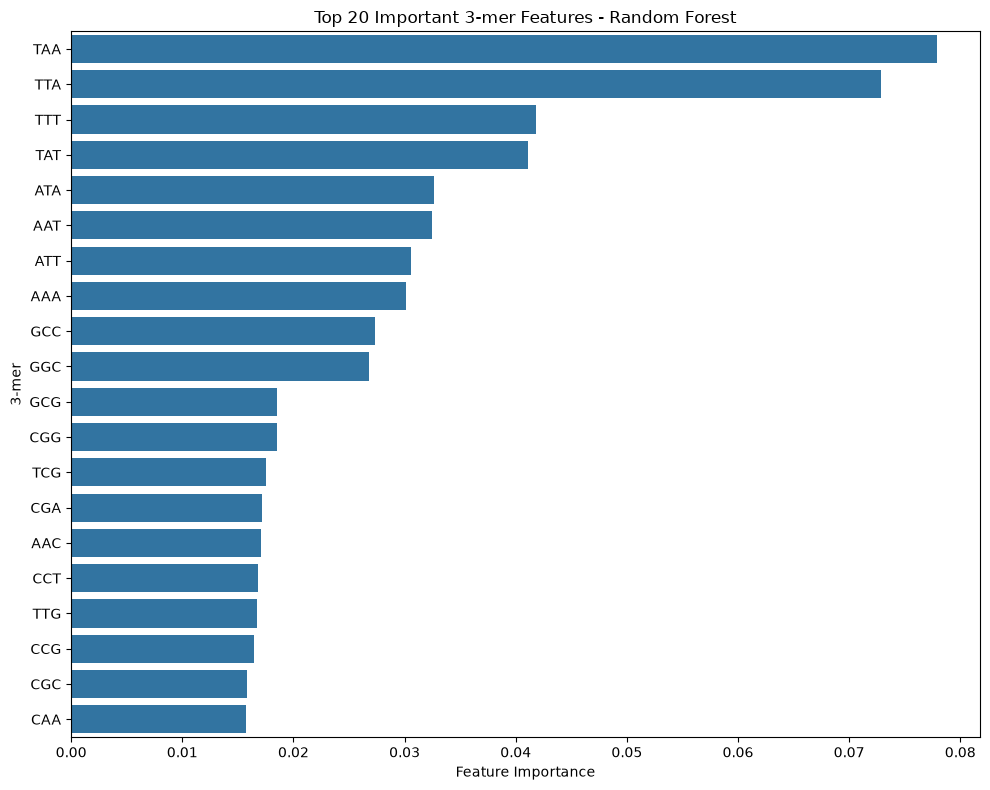

In [229]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve the trained Random Forest model
rf_best = rf_models["3-mer-only"]

# Extract feature importance
importance_df = pd.DataFrame({
    "3-mer": X_kmer.columns,
    "Importance": rf_best.feature_importances_
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
display(importance_df.head(20))

# Plot top 20 features
plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_df.head(20),
    x="Importance",
    y="3-mer"
)

plt.title("Top 20 Important 3-mer Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

,3-mer,Mean_Importance,Std_Importance
46,GCG,0.017712317321,0.002567741536
20,TTA,0.010890449479,0.002543439001
59,CGC,0.010755145292,0.003205320750
16,TAA,0.010039795705,0.002436991090
51,CAC,0.009195630950,0.001578567017
38,GTG,0.008769657386,0.001462159678
44,GCA,0.008345039725,0.002208024897
4,ATA,0.008093629727,0.002223371119
61,CCT,0.006208167810,0.001339910898
37,GTT,0.006078290968,0.001691081960


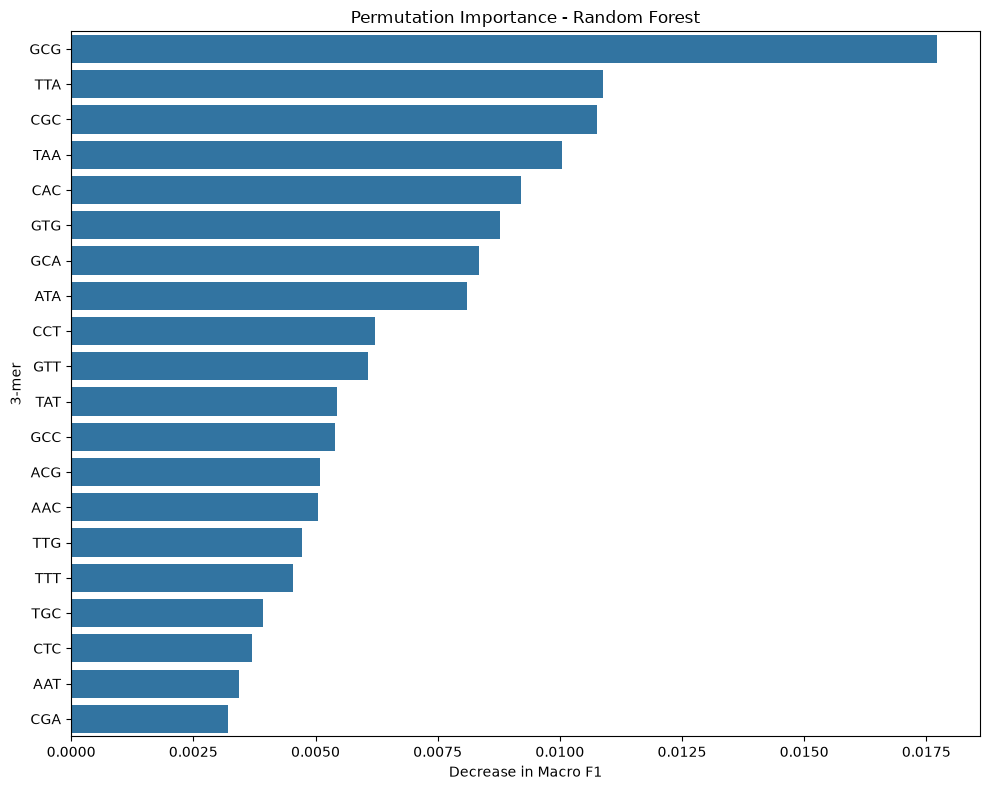

In [230]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the existing test set
X_test_kmer = X_kmer.iloc[test_idx]

# Calculate permutation importance
perm_result = permutation_importance(
    rf_best,
    X_test_kmer,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create results table
permutation_df = pd.DataFrame({
    "3-mer": X_kmer.columns,
    "Mean_Importance": perm_result.importances_mean,
    "Std_Importance": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Mean_Importance",
    ascending=False
)

display(permutation_df.head(20))

# Plot top 20
plt.figure(figsize=(10, 8))

sns.barplot(
    data=permutation_df.head(20),
    x="Mean_Importance",
    y="3-mer"
)

plt.title("Permutation Importance - Random Forest")
plt.xlabel("Decrease in Macro F1")
plt.ylabel("3-mer")

plt.tight_layout()
plt.show()

In [231]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Split GC and k-mer features
gc_train = X_gc.iloc[train_idx]
gc_test = X_gc.iloc[test_idx]

kmer_train = X_kmer.iloc[train_idx]
kmer_test = X_kmer.iloc[test_idx]

# Prepare residual feature matrices
kmer_train_res = pd.DataFrame(
    index=kmer_train.index,
    columns=kmer_columns,
    dtype=float
)

kmer_test_res = pd.DataFrame(
    index=kmer_test.index,
    columns=kmer_columns,
    dtype=float
)

# Fit GC regression using training data only
gc_models = {}

for kmer in kmer_columns:

    regression = LinearRegression()

    regression.fit(
        gc_train,
        kmer_train[kmer]
    )

    kmer_train_res[kmer] = (
        kmer_train[kmer] -
        regression.predict(gc_train)
    )

    kmer_test_res[kmer] = (
        kmer_test[kmer] -
        regression.predict(gc_test)
    )

    gc_models[kmer] = regression

# Train classifier on GC-adjusted 3-mer features
residual_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

residual_model.fit(kmer_train_res, y_train)

# Evaluate
residual_pred = residual_model.predict(kmer_test_res)

residual_accuracy = accuracy_score(
    y_test,
    residual_pred
)

residual_macro_f1 = f1_score(
    y_test,
    residual_pred,
    average="macro"
)

# Compare results
comparison_df = pd.DataFrame([
    {
        "Feature_Set": "GC-only",
        "Accuracy": 0.573766603416,
        "Macro_F1": 0.542998871778
    },
    {
        "Feature_Set": "Original 3-mer",
        "Accuracy": 0.821869070209,
        "Macro_F1": 0.809805381159
    },
    {
        "Feature_Set": "GC-adjusted 3-mer",
        "Accuracy": residual_accuracy,
        "Macro_F1": residual_macro_f1
    }
])

display(comparison_df)

,Feature_Set,Accuracy,Macro_F1
0,GC-only,0.573766603416,0.542998871778
1,Original 3-mer,0.821869070209,0.809805381159
2,GC-adjusted 3-mer,0.624288425047,0.619102183000


In [232]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Predict using GC-adjusted 3-mer features
residual_pred = residual_model.predict(kmer_test_res)

# Detailed classification report
print("GC-adjusted 3-mer Classification Report")

print(
    classification_report(
        y_test,
        residual_pred,
        digits=4
    )
)

# Confusion matrix
cm_residual = confusion_matrix(
    y_test,
    residual_pred,
    labels=residual_model.classes_
)

cm_residual_df = pd.DataFrame(
    cm_residual,
    index=residual_model.classes_,
    columns=residual_model.classes_
)

display(cm_residual_df)

GC-adjusted 3-mer Classification Report
                        precision    recall  f1-score   support

      Escherichia coli     0.6288    0.5733    0.5998       928
 Klebsiella pneumoniae     0.6489    0.6745    0.6614      1063
Pseudomonas aeruginosa     0.6245    0.6903    0.6558      1253
   Salmonella enterica     0.5886    0.5329    0.5594       972

              accuracy                         0.6243      4216
             macro avg     0.6227    0.6178    0.6191      4216
          weighted avg     0.6233    0.6243    0.6227      4216



,Escherichia coli,Klebsiella pneumoniae,Pseudomonas aeruginosa,Salmonella enterica
Escherichia coli,532,111,202,83
Klebsiella pneumoniae,76,717,136,134
Pseudomonas aeruginosa,128,115,865,145
Salmonella enterica,110,162,182,518


In [233]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

feature_sets = {
    "GC-only": X_gc,
    "3-mer-only": X_kmer,
    "Combined": X_combined
}

svm_results = []
svm_models = {}

for name, X in feature_sets.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1,
            gamma="scale"
        ))
    ])

    model.fit(X.iloc[train_idx], y_train)

    pred = model.predict(X.iloc[test_idx])

    svm_results.append({
        "Feature_Set": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro_F1": f1_score(y_test, pred, average="macro")
    })

    svm_models[name] = model

svm_results_df = pd.DataFrame(svm_results)

display(svm_results_df)

,Feature_Set,Accuracy,Macro_F1
0,GC-only,0.596774193548,0.569962169875
1,3-mer-only,0.834914611006,0.823584333645
2,Combined,0.835863377609,0.824620918986


In [234]:
import pandas as pd

final_results = pd.concat([
    pd.DataFrame([
        {"Model": "Logistic Regression", **row}
        for row in results
    ]),
    pd.DataFrame([
        {"Model": "Random Forest", **row}
        for row in rf_results
    ]),
    pd.DataFrame([
        {"Model": "SVM", **row}
        for row in svm_results
    ])
], ignore_index=True)

final_results = final_results.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

display(final_results)

print("\nBest configuration:")
display(final_results.iloc[[0]])

,Model,Feature_Set,Accuracy,Macro_F1
0,SVM,Combined,0.835863377609,0.824620918986
1,SVM,3-mer-only,0.834914611006,0.823584333645
2,Logistic Regression,3-mer-only,0.821869070209,0.809805381159
3,Logistic Regression,Combined,0.821631878558,0.809547448843
4,Random Forest,3-mer-only,0.797201138520,0.785683187515
5,Random Forest,Combined,0.796015180266,0.785007431332
6,SVM,GC-only,0.596774193548,0.569962169875
7,Random Forest,GC-only,0.588946869070,0.568593712060
8,Logistic Regression,GC-only,0.573766603416,0.542998871778



Best configuration:


,Model,Feature_Set,Accuracy,Macro_F1
0,SVM,Combined,0.835863377609,0.824620918986


In [235]:
from pathlib import Path

FIGURES_DIR = Path("results/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "figure_name.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>


# Conclusion and Final Remarks

##  Overall Results

This project investigated the classification of four bacterial species using genomic DNA fragments represented by GC content and normalized 3-mer frequency features.

Three machine learning algorithms were evaluated:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)

## Best Model Performance

The best observed performance was achieved by the **SVM model using combined GC and 3-mer features**.

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 83.59% |
| Macro F1-score | 82.46% |

The SVM model using 3-mer features alone achieved very similar performance:

- Accuracy: 83.49%
- Macro F1-score: 82.36%

These results indicate that 3-mer frequency features provided useful classification information in the evaluated dataset.

##  Key Findings

1. 3-mer-based models outperformed GC-only models.
2. SVM achieved the highest observed classification performance.
3. Combining GC content with 3-mer features provided only a marginal improvement over 3-mer features alone.
4. Classification errors were particularly observed between *E. coli* and *Salmonella enterica*.
5. GC-adjusted feature analysis showed reduced classification performance compared with the original 3-mer representation.

##  Study Limitations

This is an exploratory study based on four reference genomes, with one genome representing each species.

Although 21,077 DNA fragments were analyzed, they originated from only four independent genomes. Therefore, the fragment-level random train/test split does not establish generalization to unseen genomes or bacterial strains.

The reported performance should be interpreted within the selected reference genomes and not as independently validated species-level generalization.

## Future Directions

Future work may investigate:

- Multiple independent genomes per bacterial species.
- Genome-level validation strategies.
- Different k-mer lengths and sequence representations.
- Feature selection and dimensionality reduction.
- Advanced machine learning and deep learning approaches.
- Generalization across unseen bacterial strains.

---

##  Project Author

**Abubaker Izzeldeen Babelkhair**

Bioinformatics | Computational Biology | Machine Learning

GitHub: https://github.com/engabubakerib-dot

**End of Project**